# Proyecto de predicción de siniestralidad vial en Bogotá
## Diagnóstico inicial de datos

**Objetivo:** verificar la estructura y calidad de los registros del archivo **ACCIDENTE.csv** con el propósito de identificar las características de la información disponible y preparar la exploración de los datos correspondiente a la Entrega 1 del proyecto.

Los resultados obtenidos durante la exploración permiten reconocer la distribución de los registros, identificar valores faltantes y detectar posibles inconsistencias en la información, por lo que su interpretación debe considerar la calidad y cobertura de los datos disponibles.

### 1. Carga del archivo CSV y consulta de su estructura

Se utiliza `utf-8-sig` para reconocer el encabezado correctamente, ya que el CSV original tiene marca BOM de UTF-8, no se modifica el archivo fuente.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import csv
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ARCHIVO = Path("/content/ACCIDENTE.csv")

with ARCHIVO.open("r", encoding="utf-8-sig", newline="") as archivo:
    lector = csv.DictReader(archivo)
    columnas = lector.fieldnames or []
    registros = list(lector)

print(f"Total de registros: {len(registros)}")
print(f"Total de columnas: {len(columnas)}")

Total de registros: 906664
Total de columnas: 23


### 2. Vista previa de datos

Se muestran solo cinco filas y seis variables clave, para observar la información sin imprimir las 23 columnas completas.

In [3]:
columnas_clave = ["CODIGO_ACCIDENTE","FECHA_OCURRENCIA_ACC","LOCALIDAD","GRAVEDAD","CLASE_ACC","BARRIO"]

tabla = pd.DataFrame(registros)
display(tabla[columnas_clave].head(5))

,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,LOCALIDAD,GRAVEDAD,CLASE_ACC,BARRIO
0,4484660,2017/06/12 00:00:00+00,ENGATIVA,SOLO DANOS,CHOQUE,BONANZA
1,449558,2012/12/15 00:00:00+00,CHAPINERO,SOLO DANOS,CHOQUE,EL REFUGIO
2,513150,2014/10/26 00:00:00+00,ENGATIVA,CON HERIDOS,ATROPELLO,LAS FERIAS
3,443270,2012/10/15 00:00:00+00,FONTIBON,SOLO DANOS,CHOQUE,CIUDAD HAYUELOS
4,4412699,2015/05/11 00:00:00+00,CIUDAD BOLIVAR,SOLO DANOS,CHOQUE,PERDOMO ALTO


### 3. Calidad de los datos

Se revisa la existencia de celdas vacías, códigos de accidente repetidos y/o valores especiales como `SIN_NMG`. Estos últimos no se cuentan automáticamente como vacíos, su significado debe validarse en el diccionario oficial de datos.

In [4]:
# Preparación de los datos
df = pd.DataFrame(registros)
df = df.replace(r"^\s*$", pd.NA, regex=True)

# Identificación de valores vacíos
vacios = df.isna().sum()
tabla_vacios = pd.DataFrame({
    "Columna": vacios.index,
    "Valores vacíos": vacios.values,
    "Porcentaje (%)": (vacios.values / len(df) * 100).round(2)
})
tabla_vacios = tabla_vacios[tabla_vacios["Valores vacíos"] > 0].sort_values("Valores vacíos", ascending=False)

print("1. Valores vacíos por columna")
display(tabla_vacios)

1. Valores vacíos por columna


,Columna,Valores vacíos,Porcentaje (%)
21,MVINOMBRE,10458,1.15
19,PK_CALZADA,2307,0.25
18,CIV,1828,0.20
12,CLASE_ACC,280,0.03
20,BARRIO,86,0.01
11,GRAVEDAD,6,0.00


In [5]:
# Identificación de registros duplicados
codigos = df["CODIGO_ACCIDENTE"].dropna().str.strip()
duplicados = codigos.duplicated().sum()

# Identificación de nombres no especificados
sin_nombre = (df["MVINOMBRE"].fillna("").str.strip().str.upper().eq("SIN_NMG").sum())

# Resumen de calidad de datos
resumen = pd.DataFrame({
    "Indicador": ["Total de registros","Códigos de accidente duplicados","Registros con MVINOMBRE = SIN_NMG"],
    "Cantidad":[len(df),duplicados,sin_nombre]
})
print("Resumen de calidad de datos")
display(resumen)

Resumen de calidad de datos


,Indicador,Cantidad
0,Total de registros,906664
1,Códigos de accidente duplicados,0
2,Registros con MVINOMBRE = SIN_NMG,429155


### 4. Fechas y categorías

Este análisis revela qué años y localidades aparecen en el archivo de prueba, las fechas se interpretan desde los diez primeros caracteres (AAAA/MM/DD) para evitar problemas con el sufijo de zona horaria del CSV las horas se analizarán después.

In [6]:
# Análisis de fechas
fechas = pd.to_datetime(df["FECHA_OCURRENCIA_ACC"].astype("string").str[:10].str.replace("/", "-"),format="%Y-%m-%d",errors="coerce")
tabla_fechas = pd.DataFrame({
    "Total de registros": [len(df)],
    "Fechas válidas": [fechas.notna().sum()],
    "Fechas no válidas": [fechas.isna().sum()],
    "Fecha inicial": [fechas.min().date() if fechas.notna().any() else "Sin datos"],
    "Fecha final": [fechas.max().date() if fechas.notna().any() else "Sin datos"]
})

print("Resumen de fechas")
display(tabla_fechas)

Resumen de fechas


,Total de registros,Fechas válidas,Fechas no válidas,Fecha inicial,Fecha final
0,906664,906664,0,2001-01-15,2026-10-18


In [7]:
# Distribución de variables
columnas_analisis = ["LOCALIDAD", "GRAVEDAD", "CLASE_ACC"]
for columna in columnas_analisis:
    datos = (df[columna].fillna("").astype(str).str.strip().replace("", "(vacío)"))
    conteos = datos.value_counts()
    tabla_distribucion = pd.DataFrame({
        "Categoría": conteos.index,
        "Cantidad": conteos.values,
        "Porcentaje (%)": (conteos.values / len(df) * 100).round(2)
    })

    print(f"Distribución de {columna}")
    display(tabla_distribucion)

Distribución de LOCALIDAD


,Categoría,Cantidad,Porcentaje (%)
0,KENNEDY,105340,11.62
1,ENGATIVA,93225,10.28
2,SUBA,92345,10.19
3,USAQUEN,90089,9.94
4,FONTIBON,70085,7.73
5,PUENTE ARANDA,65165,7.19
6,CHAPINERO,62975,6.95
7,TEUSAQUILLO,49660,5.48
8,BARRIOS UNIDOS,47552,5.24
9,BOSA,36487,4.02


Distribución de GRAVEDAD


,Categoría,Cantidad,Porcentaje (%)
0,SOLO DANOS,560035,61.77
1,CON HERIDOS,331024,36.51
2,CON MUERTOS,15599,1.72
3,(vacío),6,0.00


Distribución de CLASE_ACC


,Categoría,Cantidad,Porcentaje (%)
0,CHOQUE,751972,82.94
1,ATROPELLO,106548,11.75
2,CAIDA DE OCUPANTE,20663,2.28
3,VOLCAMIENTO,11921,1.31
4,OTRO,10776,1.19
5,AUTOLESION,4415,0.49
6,(vacío),280,0.03
7,INCENDIO,89,0.01


### 5. Visualización de registros de accidentes por localidad
Se presenta la distribución de los accidentes de tránsito registrados en las diferentes localidades de Bogotá, con el propósito de identificar cuáles presentan una mayor cantidad de registros y facilitar la comparación de los resultados mediante un gráfico de barras.

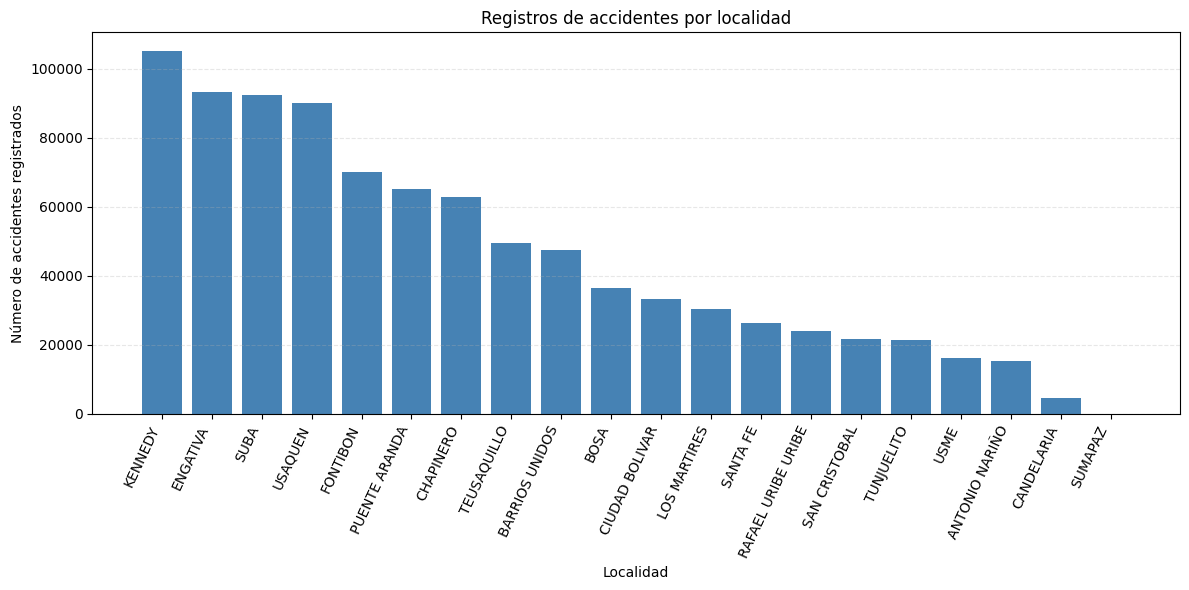

In [8]:
# Agrupación de accidentes por localidad
frecuencias = (df["LOCALIDAD"].fillna("Sin información").replace("", "Sin información").value_counts())

# Configuración del gráfico
plt.figure(figsize=(12, 6))
plt.bar(frecuencias.index,frecuencias.values,color="steelblue")
plt.title("Registros de accidentes por localidad")
plt.xlabel("Localidad")
plt.ylabel("Número de accidentes registrados")
plt.xticks(rotation=65, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### 6. Comportamiento temporal de los siniestros

 Este apartado queremos identificar cómo ha cambiado la cantidad de siniestros a lo largo del tiempo, si existen aumentos o disminuciones y qué patrones temporales pueden resultar útiles para nuestro modelo predictivo.

Agruparemos inicialmente los datos por año solo con fines exploratorios. Esto no significa que el modelo ni el futuro tablero deban limitarse a periodos anuales.

In [9]:
# Preparación de los datos
datos = pd.DataFrame(registros)
fechas = pd.to_datetime(datos["FECHA_OCURRENCIA_ACC"].astype(str).str[:10].str.replace("/", "-", regex=False),format="%Y-%m-%d",errors="coerce")

# Agrupación de accidentes por año
accidentes_anuales = fechas.dt.year.value_counts().sort_index()
tabla_anual = (accidentes_anuales.rename_axis("Año").reset_index(name="Cantidad de siniestros"))

# Visualización de la tabla
display(tabla_anual)

,Año,Cantidad de siniestros
0,2001,2
1,2002,202
2,2003,282
3,2005,432
4,2006,368
5,2007,59541
6,2008,56920
7,2009,44278
8,2010,53656
9,2011,55717


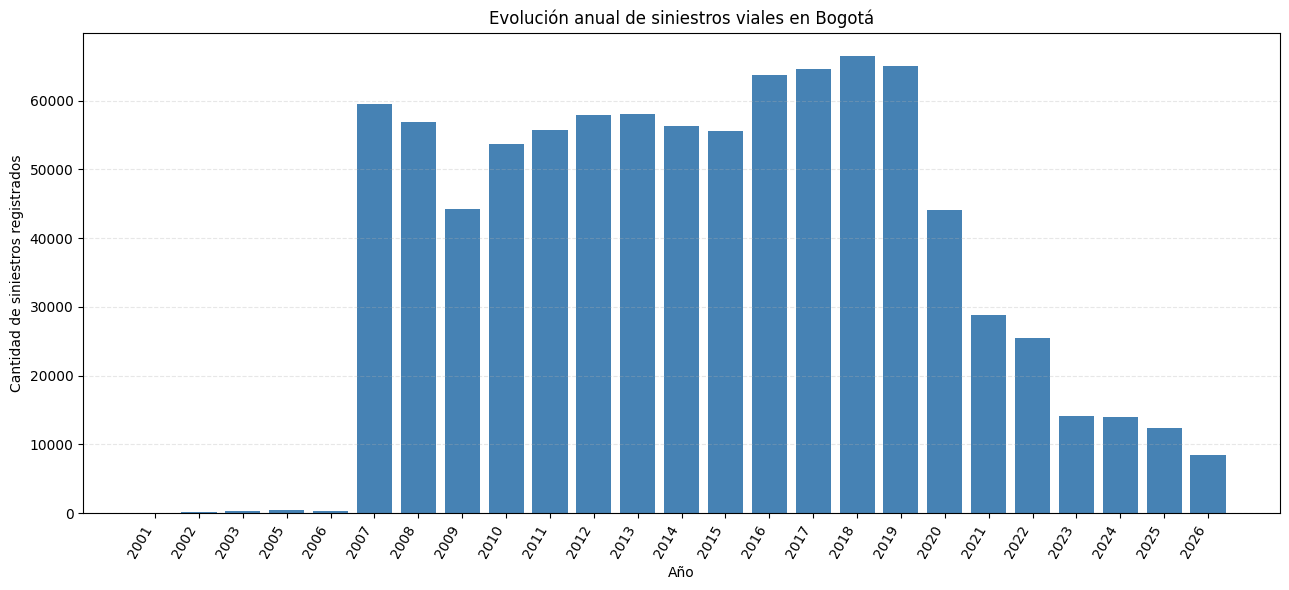

In [10]:
#Gráfico de accidentes por año
plt.figure(figsize=(13, 6))
plt.bar(tabla_anual["Año"].astype(str),tabla_anual["Cantidad de siniestros"],color="steelblue")
plt.title("Evolución anual de siniestros viales en Bogotá")
plt.xlabel("Año")
plt.ylabel("Cantidad de siniestros registrados")
plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### 7. Conclusiones de este diagnóstico inicial

El diagnóstico inicial de la base **ACCIDENTE.csv** permite identificar un total de 906.546 registros de accidentes de tránsito en Bogotá, correspondientes al periodo comprendido entre el 15 de enero de 2001 y el 16 de octubre de 2026, sin encontrar fechas inválidas ni códigos de accidente duplicados.

En relaciòn a la calidad de los datos se identifican algunos valores vacíos en las columnas **MVINOMBRE, PK_CALZADA, CIV, CLASE_ACC, BARRIO y GRAVEDAD** aunque sus porcentajes son relativamente bajos, también se encuentran 429.097 registros con el valor SIN_NMG en MVINOMBRE, situación que requiere una revisión adicional para determinar su significado y tratamiento.

Respecto a la distribución de los accidentes tanto **Kennedy, Engativá y Suba** presentan la mayor cantidad de registros, mientras que los accidentes clasificados como solo daños representan el 61,78 % y los choques constituyen el 82,94 % de los casos, lo que permite reconocer algunas características generales de la siniestralidad vial registrada en la ciudad.

Estos resultados proporcionan una primera aproximación al comportamiento de los datos y permiten establecer una base para continuar con el análisis exploratorio, la preparación de la información y la identificación de variables que puedan contribuir al desarrollo de una solución analítica orientada a la predicción de la siniestralidad vial en Bogotá.

## Continuación y profundización del análisis exploratorio

El diagnóstico inicial permitió reconocer la estructura general del conjunto de datos de siniestralidad vial de Bogotá, sus principales variables y las primeras condiciones de calidad.

A partir de estos resultados se desarrolló una segunda etapa de análisis, orientada a profundizar en la consistencia temporal, la distribución territorial, los cambios en los mecanismos de registro y la identificación de patrones relevantes para la predicción.

Se conservaron los procedimientos del diagnóstico inicial con el propósito de mantener la trazabilidad metodológica del proyecto. Las modificaciones efectuadas para adaptar su ejecución a Google Colab se limitaron a aspectos operativos, como la configuración de las rutas de acceso a los archivos.

La ampliación incorpora procedimientos adicionales de validación, visualización y construcción de variables históricas, manteniendo una secuencia reproducible entre la exploración inicial y la preparación para el modelamiento.


## Version avanzada del EDA ##


In [11]:

# ======================================================
# EDA AVANZADO - SINIESTRALIDAD VIAL BOGOTÁ
# 01. VERIFICACIÓN DEL DATASET
# ======================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="viridis"
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120

# Archivo visible en el panel de Colab
ruta = Path("/content/ACCIDENTE.csv")

if not ruta.exists():
    raise FileNotFoundError(
        "No encuentro ACCIDENTE.csv en /content/. "
        "Verifica el archivo en el panel izquierdo."
    )

df_eda = pd.read_csv(
    ruta,
    encoding="utf-8-sig",
    low_memory=False
)

print("=" * 55)
print("DIAGNÓSTICO DEL CONJUNTO DE DATOS")
print("=" * 55)

print(f"Registros: {df_eda.shape[0]:,}")
print(f"Columnas: {df_eda.shape[1]}")
print(f"Tamaño en memoria: "
      f"{df_eda.memory_usage(deep=True).sum()/1024**2:.2f} MB")

print("\nCOLUMNAS DISPONIBLES:")
for i, columna in enumerate(df_eda.columns, 1):
    print(f"{i:02d}. {columna}")

print("\nPRIMEROS REGISTROS:")
display(df_eda.head())


DIAGNÓSTICO DEL CONJUNTO DE DATOS
Registros: 906,664
Columnas: 23
Tamaño en memoria: 753.37 MB

COLUMNAS DISPONIBLES:
01. X
02. Y
03. OBJECTID
04. FORMULARIO
05. CODIGO_ACCIDENTE
06. FECHA_OCURRENCIA_ACC
07. HORA_OCURRENCIA_ACC
08. ANO_OCURRENCIA_ACC
09. MES_OCURRENCIA_ACC
10. DIA_OCURRENCIA_ACC
11. DIRECCION
12. GRAVEDAD
13. CLASE_ACC
14. LOCALIDAD
15. MUNICIPIO
16. FECHA_HORA_ACC
17. LATITUD
18. LONGITUD
19. CIV
20. PK_CALZADA
21. BARRIO
22. MVINOMBRE
23. DISTANCIA_VIA

PRIMEROS REGISTROS:


,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,HORA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,MES_OCURRENCIA_ACC,DIA_OCURRENCIA_ACC,...,LOCALIDAD,MUNICIPIO,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA,BARRIO,MVINOMBRE,DISTANCIA_VIA
0,-74.090924,4.693807,1,A000640275,4484660,2017/06/12 00:00:00+00,05:30:00,2017,JUNIO,LUNES,...,ENGATIVA,BOGOTA DC,2017/06/12 05:30:00+00,4.693807,-74.090924,10006772.0,221236.0,BONANZA,AVENIDA BOYACA,0.6
1,-74.040677,4.669288,3,A1241594,449558,2012/12/15 00:00:00+00,20:30:00,2012,DICIEMBRE,SABADO,...,CHAPINERO,BOGOTA DC,2012/12/15 20:30:00+00,4.669288,-74.040677,2002328.0,35683.0,EL REFUGIO,SIN_NMG,14.4
2,-74.087407,4.679568,5,A000035070,513150,2014/10/26 00:00:00+00,21:25:00,2014,OCTUBRE,DOMINGO,...,ENGATIVA,BOGOTA DC,2014/10/26 21:25:00+00,4.679568,-74.087407,10008600.0,43287.0,LAS FERIAS,AVENIDA CHILE,2.5
3,-74.133350,4.662473,6,A1236472,443270,2012/10/15 00:00:00+00,18:00:00,2012,OCTUBRE,LUNES,...,FONTIBON,BOGOTA DC,2012/10/15 18:00:00+00,4.662473,-74.133350,50007085.0,50015411.0,CIUDAD HAYUELOS,AVENIDA CIUDAD DE CALI,0.9
4,-74.166937,4.587187,7,A000200705,4412699,2015/05/11 00:00:00+00,10:50:00,2015,MAYO,LUNES,...,CIUDAD BOLIVAR,BOGOTA DC,2015/05/11 10:50:00+00,4.587187,-74.166937,19001483.0,136166.0,PERDOMO ALTO,SIN_NMG,2.7


,Tipo de dato,No nulos,Nulos,Nulos (%),Valores únicos
MVINOMBRE,object,903506,3158,0.35%,130
PK_CALZADA,float64,904357,2307,0.25%,99992
CIV,float64,904836,1828,0.20%,83798
CLASE_ACC,object,906384,280,0.03%,7
BARRIO,object,906578,86,0.01%,1020
GRAVEDAD,object,906658,6,0.00%,3
X,float64,906664,0,0.00%,251388
HORA_OCURRENCIA_ACC,object,906664,0,0.00%,1440
FECHA_OCURRENCIA_ACC,object,906664,0,0.00%,7740
CODIGO_ACCIDENTE,int64,906664,0,0.00%,906664



REGISTROS DUPLICADOS COMPLETOS:
0


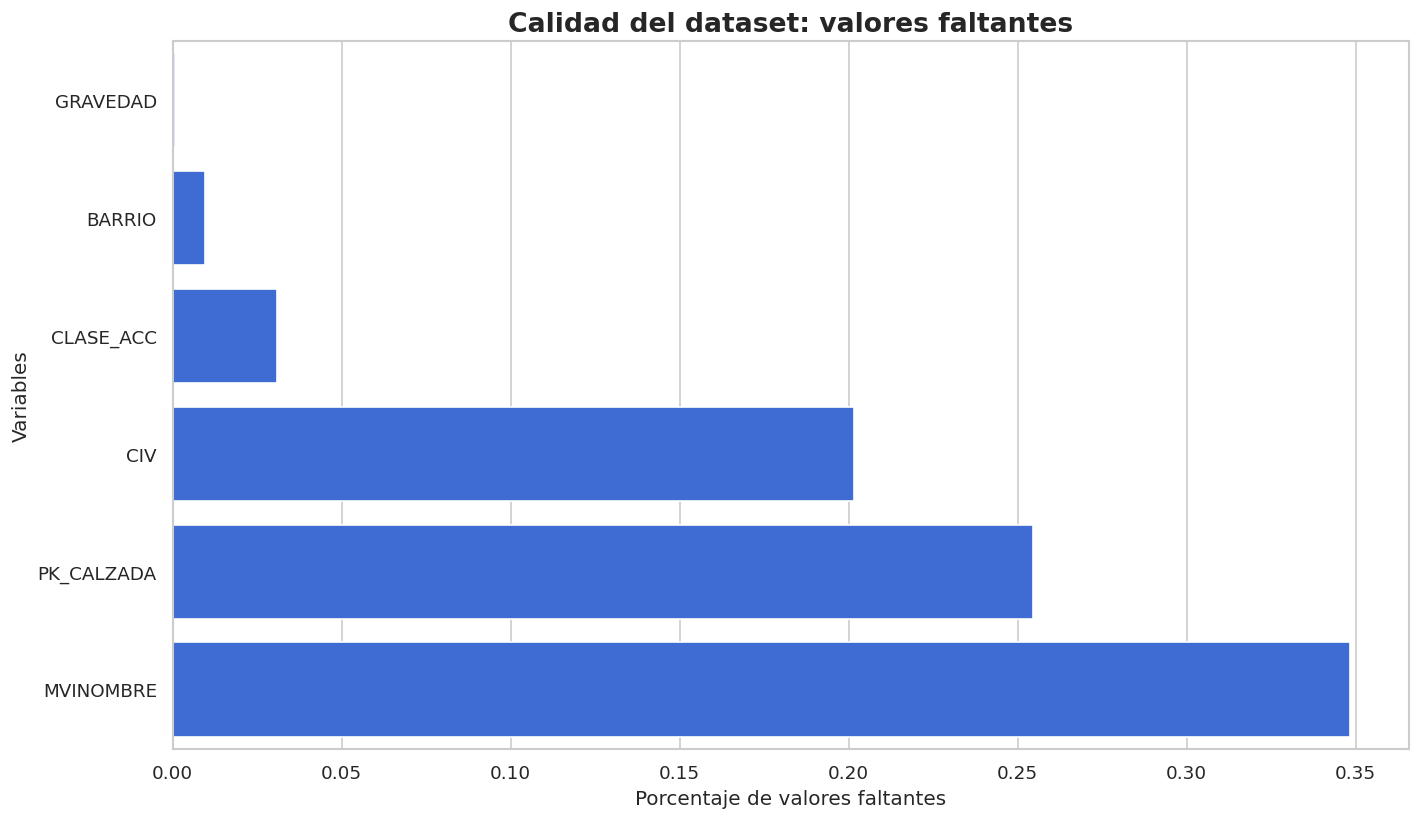

In [12]:

# ======================================================
# 02. CALIDAD Y COMPLETITUD DE LOS DATOS
# ======================================================

calidad = pd.DataFrame({
    "Tipo de dato": df_eda.dtypes.astype(str),
    "No nulos": df_eda.notna().sum(),
    "Nulos": df_eda.isna().sum(),
    "Nulos (%)": df_eda.isna().mean() * 100,
    "Valores únicos": df_eda.nunique(dropna=True)
})

calidad = calidad.sort_values(
    "Nulos (%)", ascending=False
)

display(
    calidad.style
    .format({"Nulos (%)": "{:.2f}%"})
    .background_gradient(
        subset=["Nulos (%)"], cmap="YlOrRd"
    )
)

print("\nREGISTROS DUPLICADOS COMPLETOS:")
print(df_eda.duplicated().sum())

# Visualización de datos faltantes
faltantes = calidad[
    calidad["Nulos (%)"] > 0
].sort_values("Nulos (%)")

if not faltantes.empty:
    plt.figure(figsize=(12, 7))

    ax = sns.barplot(
        x=faltantes["Nulos (%)"],
        y=faltantes.index,
        color="#2563eb"
    )

    plt.title(
        "Calidad del dataset: valores faltantes",
        fontsize=16, fontweight="bold"
    )
    plt.xlabel("Porcentaje de valores faltantes")
    plt.ylabel("Variables")
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron valores nulos.")


### Hallazgos del análisis de calidad

El conjunto de datos ACCIDENTE contiene 906.664 registros y 23 variables. La evaluación inicial evidencia una alta completitud de la información, con porcentajes de valores nulos inferiores al 0,35 % en todas las variables.

Las principales ausencias se encuentran en MVINOMBRE (3.158 registros), PK_CALZADA (2.307) y CIV (1.828). Por su parte, las variables LOCALIDAD, FECHA_OCURRENCIA_ACC y CODIGO_ACCIDENTE no presentan valores nulos, lo cual constituye una condición favorable para el análisis geográfico y temporal propuesto.

Adicionalmente, no se identificaron registros completamente duplicados y el código de accidente presenta un valor único para cada observación.

Estos resultados sugieren que el conjunto de datos ofrece una base adecuada para continuar con la exploración. No obstante, antes del modelamiento será necesario verificar la validez de las fechas, la consistencia de las categorías, la cobertura temporal y la presencia de valores que representen información desconocida sin estar codificados como nulos.


In [13]:
# ==================================================
# 03. AUDITORÍA AVANZADA DE CALIDAD DE DATOS
# ==================================================

import pandas as pd
import numpy as np

# Trabajamos sobre una copia
eda = df_eda.copy()

# Normalizar únicamente columnas críticas
columnas_categoricas = [
    "LOCALIDAD", "GRAVEDAD", "CLASE_ACC",
    "BARRIO", "MVINOMBRE"
]

for col in columnas_categoricas:
    eda[col] = (
        eda[col].astype("string")
        .str.strip().str.upper()
    )

# Interpretar fechas; conservamos la fecha original
eda["FECHA_ANALISIS"] = pd.to_datetime(
    eda["FECHA_OCURRENCIA_ACC"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

# Identificar inconsistencias
resumen = {
    "Total registros": len(eda),
    "Duplicados completos": int(eda.duplicated().sum()),
    "Códigos accidente duplicados": int(
        eda["CODIGO_ACCIDENTE"].duplicated().sum()
    ),
    "Fechas inválidas": int(
        eda["FECHA_ANALISIS"].isna().sum()
    ),
    "Localidades vacías": int(
        eda["LOCALIDAD"].isna().sum()
    ),
    "Localidades sin identificar": int(
        eda["LOCALIDAD"].isin(
            ["SIN_NMG", "SIN DATO", ""]
        ).sum()
    ),
    "Gravedad sin clasificar": int(
        eda["GRAVEDAD"].isna().sum()
    ),
    "Clase sin clasificar": int(
        eda["CLASE_ACC"].isna().sum()
    )
}

display(
    pd.DataFrame(
        resumen.items(),
        columns=["Indicador", "Cantidad"]
    )
)

print("\nCOBERTURA TEMPORAL")
print("Fecha mínima:", eda["FECHA_ANALISIS"].min())
print("Fecha máxima:", eda["FECHA_ANALISIS"].max())

print("\nLOCALIDADES REGISTRADAS")
display(
    eda["LOCALIDAD"].value_counts(
        dropna=False
    ).to_frame("Registros")
)

print("\nGRAVEDAD")
display(
    eda["GRAVEDAD"].value_counts(
        dropna=False
    ).to_frame("Registros")
)


,Indicador,Cantidad
0,Total registros,906664
1,Duplicados completos,0
2,Códigos accidente duplicados,0
3,Fechas inválidas,0
4,Localidades vacías,0
5,Localidades sin identificar,0
6,Gravedad sin clasificar,6
7,Clase sin clasificar,280



COBERTURA TEMPORAL
Fecha mínima: 2001-01-15 00:00:00
Fecha máxima: 2026-10-18 00:00:00

LOCALIDADES REGISTRADAS


,Registros
LOCALIDAD,
KENNEDY,105340
ENGATIVA,93225
SUBA,92345
USAQUEN,90089
FONTIBON,70085
PUENTE ARANDA,65165
CHAPINERO,62975
TEUSAQUILLO,49660
BARRIOS UNIDOS,47552



GRAVEDAD


,Registros
GRAVEDAD,
SOLO DANOS,560035
CON HERIDOS,331024
CON MUERTOS,15599
<NA>,6


### Hallazgos de la auditoría de calidad y consistencia

La evaluación del conjunto de datos ACCIDENTE, compuesto por 906.664 registros, evidenció la ausencia de códigos de accidente duplicados, fechas inválidas y localidades sin identificar. La información histórica disponible comprende desde el 15 de enero de 2001 hasta el 18 de octubre de 2026.

Las variables principales para el análisis territorial y temporal presentan condiciones favorables de completitud. No obstante, se identificaron seis registros sin clasificación de gravedad y 280 sin clasificación de clase de accidente, los cuales requieren tratamiento específico en los análisis descriptivos.

El análisis territorial preliminar identifica una concentración de registros en Kennedy, Engativá y Suba, que representan aproximadamente el 32,09 % de los eventos del conjunto de datos. Esta concentración corresponde a cantidades absolutas y no debe interpretarse directamente como una medida de riesgo vial.

Se reconoce igualmente la necesidad de investigar diferencias en la cobertura temporal y territorial, particularmente en los primeros años de la serie, durante 2026 y en localidades con muy pocos registros, como Sumapaz.

En consecuencia, se recomienda desarrollar la exploración temporal mensual y evaluar la consistencia de las observaciones antes de definir el periodo de entrenamiento del modelo predictivo.


,registros,meses_con_registros
FECHA_ANALISIS,,
2001,2,2
2002,202,8
2003,282,12
2005,432,12
2006,368,12
2007,59541,12
2008,56920,12
2009,44278,12
2010,53656,12


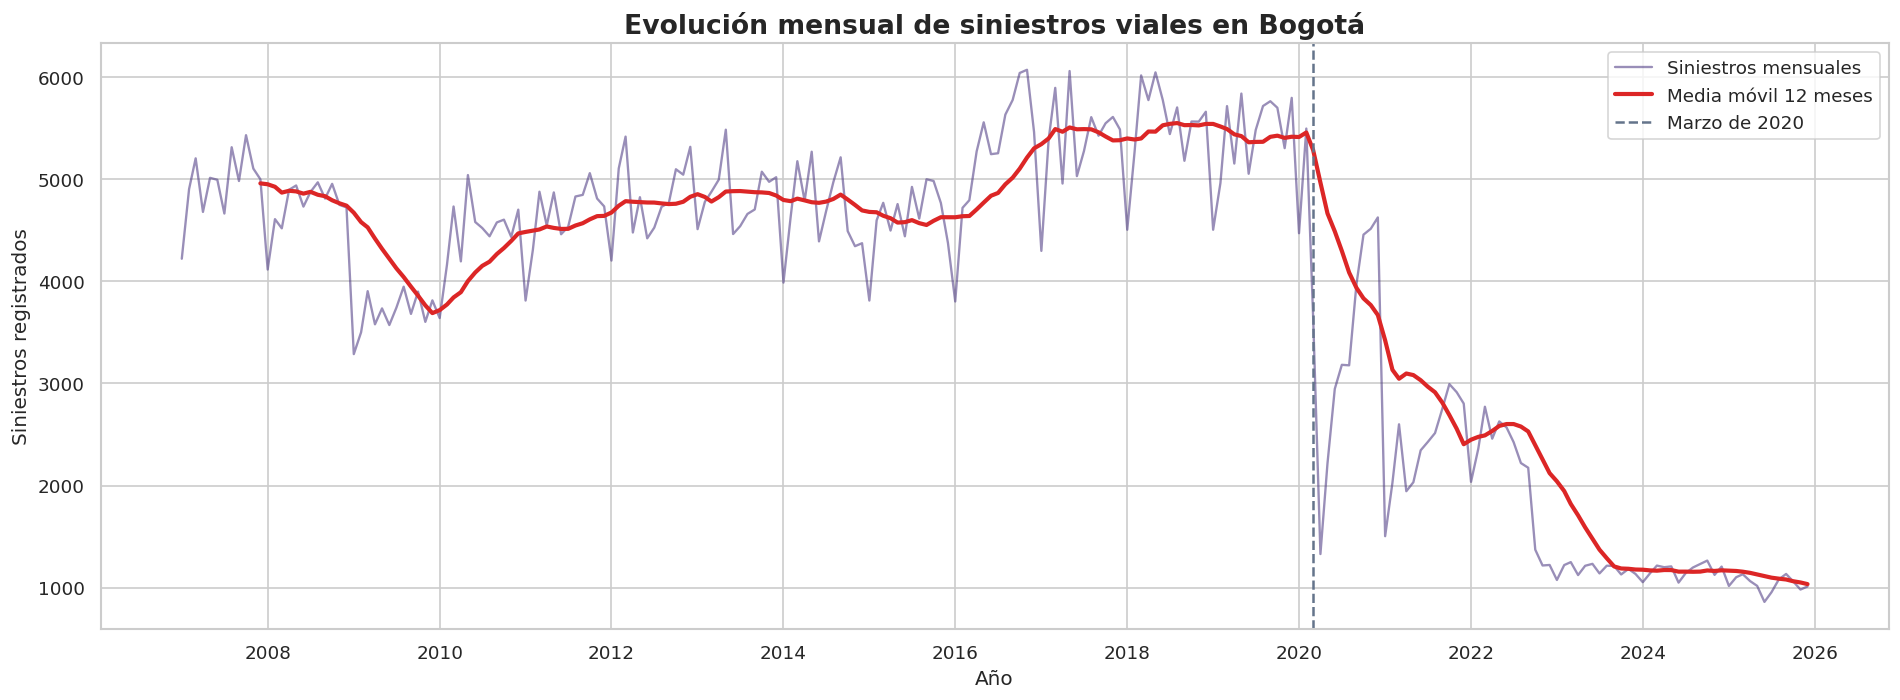

In [14]:

# ========================================================
# 04. EVOLUCIÓN TEMPORAL DE LA SINIESTRALIDAD
# ========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Agregación mensual
serie_mensual = (
    eda.dropna(subset=["FECHA_ANALISIS"])
       .set_index("FECHA_ANALISIS")
       .resample("MS")
       .size()
       .rename("siniestros")
)

# Inspección de cobertura anual
cobertura = pd.DataFrame({
    "registros": eda.groupby(
        eda["FECHA_ANALISIS"].dt.year
    ).size(),
    "meses_con_registros": eda.groupby(
        eda["FECHA_ANALISIS"].dt.year
    )["FECHA_ANALISIS"].apply(
        lambda x: x.dt.month.nunique()
    )
})

display(cobertura)

# Intervalo exploratorio provisional:
# excluye primeros años escasos y 2026 incompleto
serie_estudio = serie_mensual.loc[
    "2007-01":"2025-12"
].copy()

media_movil = (
    serie_estudio.rolling(
        window=12, min_periods=12
    ).mean()
)

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    serie_estudio.index,
    serie_estudio,
    label="Siniestros mensuales",
    alpha=0.55, linewidth=1.4
)

ax.plot(
    media_movil.index,
    media_movil,
    label="Media móvil 12 meses",
    color="#dc2626", linewidth=2.5
)

ax.axvline(
    pd.Timestamp("2020-03-01"),
    linestyle="--", color="#64748b",
    label="Marzo de 2020"
)

ax.set_title(
    "Evolución mensual de siniestros viales en Bogotá",
    fontsize=16, fontweight="bold"
)
ax.set_xlabel("Año")
ax.set_ylabel("Siniestros registrados")
ax.legend()
plt.tight_layout()
plt.show()


### Análisis de cobertura y evolución temporal

El análisis temporal del conjunto de datos ACCIDENTE revela diferencias significativas en el volumen de registros históricos. Los años anteriores a 2007 presentan cantidades reducidas y discontinuidades, incluido el año 2004, para el cual no aparecen registros.

Entre 2007 y 2019 se observa un volumen anual relativamente estable, con un máximo de 66.534 siniestros registrados en 2018. Posteriormente se identifica una reducción importante, pasando de 65.027 registros en 2019 a 44.051 en 2020, y alcanzando 12.400 en 2025.

La disminución observada entre 2019 y 2025 corresponde aproximadamente al 80,9 %. No obstante, esta variación no puede interpretarse directamente como una reducción equivalente de la siniestralidad real, dado que aún no se ha confirmado la homogeneidad de los procesos de registro y cobertura temporal.

Estos hallazgos justifican profundizar en la evolución por localidad, gravedad y clase de accidente, así como verificar posibles cambios metodológicos en la fuente. Los resultados serán determinantes para seleccionar un periodo de entrenamiento representativo y evitar sesgos derivados de discontinuidades en la información.


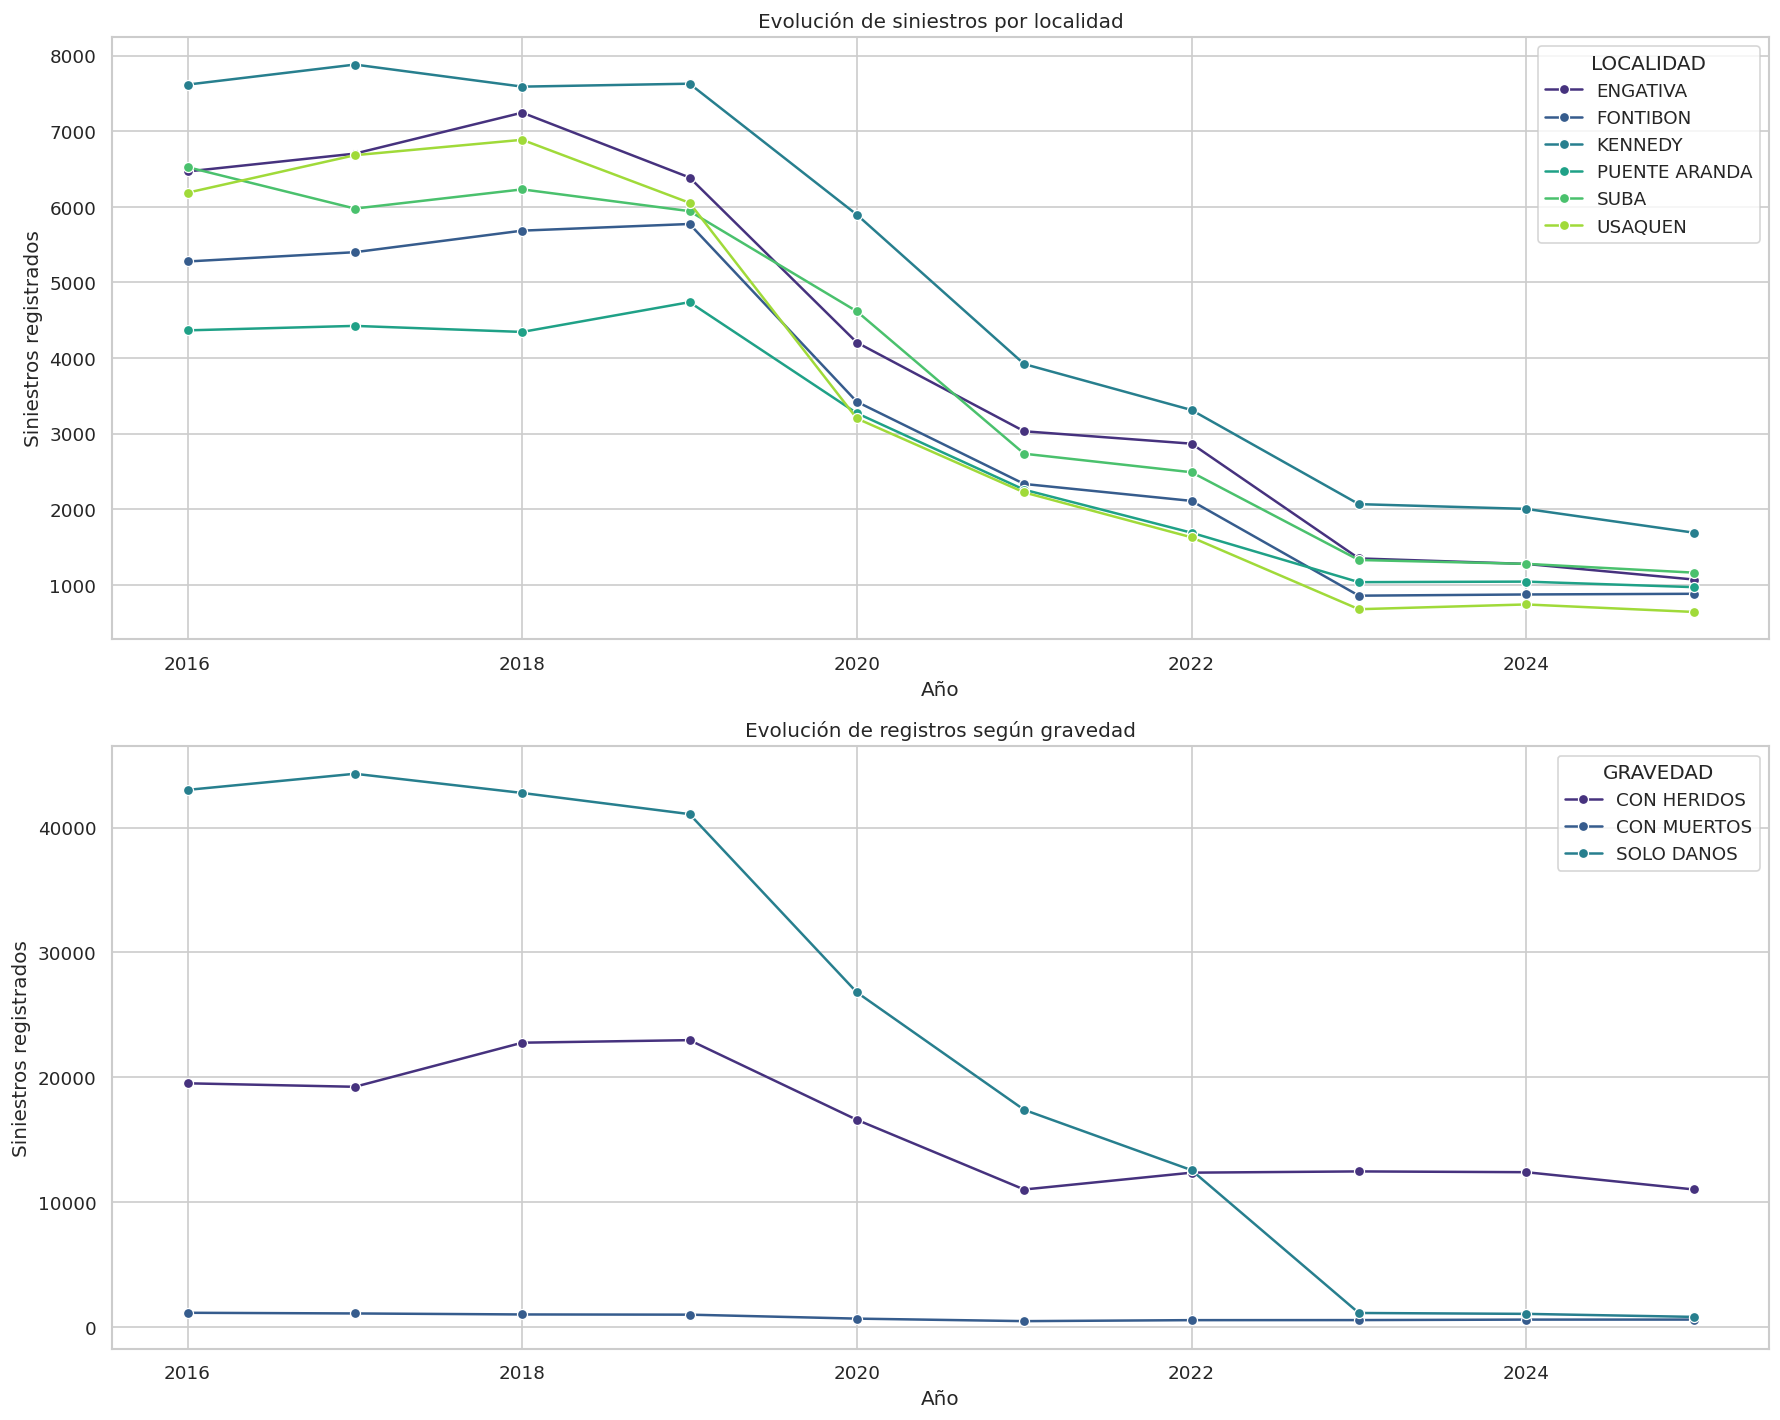

Composición porcentual de gravedad por año:


GRAVEDAD,CON HERIDOS,CON MUERTOS,SOLO DANOS
anio,,,
2016,30.65,1.78,67.57
2017,29.77,1.67,68.57
2018,34.22,1.50,64.28
2019,35.32,1.51,63.17
2020,37.66,1.51,60.84
2021,38.14,1.60,60.26
2022,48.54,2.13,49.33
2023,88.23,3.87,7.90
2024,88.39,4.17,7.45


In [15]:

# ========================================================
# 05. DIAGNÓSTICO DE CAMBIOS EN LA COBERTURA
# ========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

analisis = eda[
    eda["FECHA_ANALISIS"].dt.year.between(2016, 2025)
].copy()

analisis["anio"] = analisis["FECHA_ANALISIS"].dt.year
analisis["mes"] = analisis["FECHA_ANALISIS"].dt.month

fig, axes = plt.subplots(2, 1, figsize=(15, 12))

# A. Evolución de las principales localidades
principales = (
    analisis["LOCALIDAD"]
    .value_counts()
    .head(6).index
)

localidades_anio = (
    analisis[
        analisis["LOCALIDAD"].isin(principales)
    ]
    .groupby(["anio", "LOCALIDAD"])
    .size()
    .reset_index(name="siniestros")
)

sns.lineplot(
    data=localidades_anio,
    x="anio",
    y="siniestros",
    hue="LOCALIDAD",
    marker="o",
    ax=axes[0]
)

axes[0].set_title(
    "Evolución de siniestros por localidad"
)
axes[0].set_ylabel("Siniestros registrados")
axes[0].set_xlabel("Año")

# B. Evolución por gravedad
gravedad_anio = (
    analisis.groupby(["anio", "GRAVEDAD"])
    .size()
    .reset_index(name="siniestros")
)

sns.lineplot(
    data=gravedad_anio,
    x="anio",
    y="siniestros",
    hue="GRAVEDAD",
    marker="o",
    ax=axes[1]
)

axes[1].set_title(
    "Evolución de registros según gravedad"
)
axes[1].set_ylabel("Siniestros registrados")
axes[1].set_xlabel("Año")

plt.tight_layout()
plt.show()

# Comparación de gravedad en dos años
tabla = pd.crosstab(
    analisis["anio"],
    analisis["GRAVEDAD"],
    normalize="index"
) * 100

print("Composición porcentual de gravedad por año:")
display(tabla.round(2))


### Cambio estructural en la composición de la siniestralidad registrada

El análisis por gravedad evidencia una modificación sustancial en la composición de los siniestros viales registrados en Bogotá a partir de 2022. Mientras que en 2019 los eventos clasificados como solo daños representaban el 63,17 % de los registros, en 2023 su participación disminuyó al 7,90 %.

Esta discontinuidad coincide con un cambio normativo relevante. El artículo 16 de la Ley 2251 de 2022 y la Circular Externa 20224000000057 del Ministerio de Transporte modificaron el procedimiento de atención de siniestros con únicamente daños materiales, eliminando la obligatoriedad de elaborar el Informe Policial de Accidente de Tránsito (IPAT) para estos eventos.

La Secretaría Distrital de Movilidad ha advertido que, como consecuencia, los registros de siniestros con solo daños no son directamente comparables con los de periodos anteriores.

Por esta razón, la disminución observada en las cantidades totales no puede atribuirse exclusivamente a una reducción de la siniestralidad real. Desde la perspectiva del modelamiento predictivo, esta discontinuidad requiere definir cuidadosamente la variable objetivo, el periodo de entrenamiento y los criterios de evaluación.

**Fuentes:** Ley 2251 de 2022, artículo 16; Circular Externa 20224000000057 del Ministerio de Transporte; Secretaría Distrital de Movilidad de Bogotá, comunicación oficial de septiembre de 2024.


GRAVEDAD,CON HERIDOS,CON MUERTOS,SOLO DANOS
anio,,,
2016,19513,1131,43017
2017,19234,1077,44308
2018,22766,997,42771
2019,22970,981,41076
2020,16589,663,26799
2021,11006,462,17387
2022,12355,541,12557
2023,12455,546,1115
2024,12393,584,1044


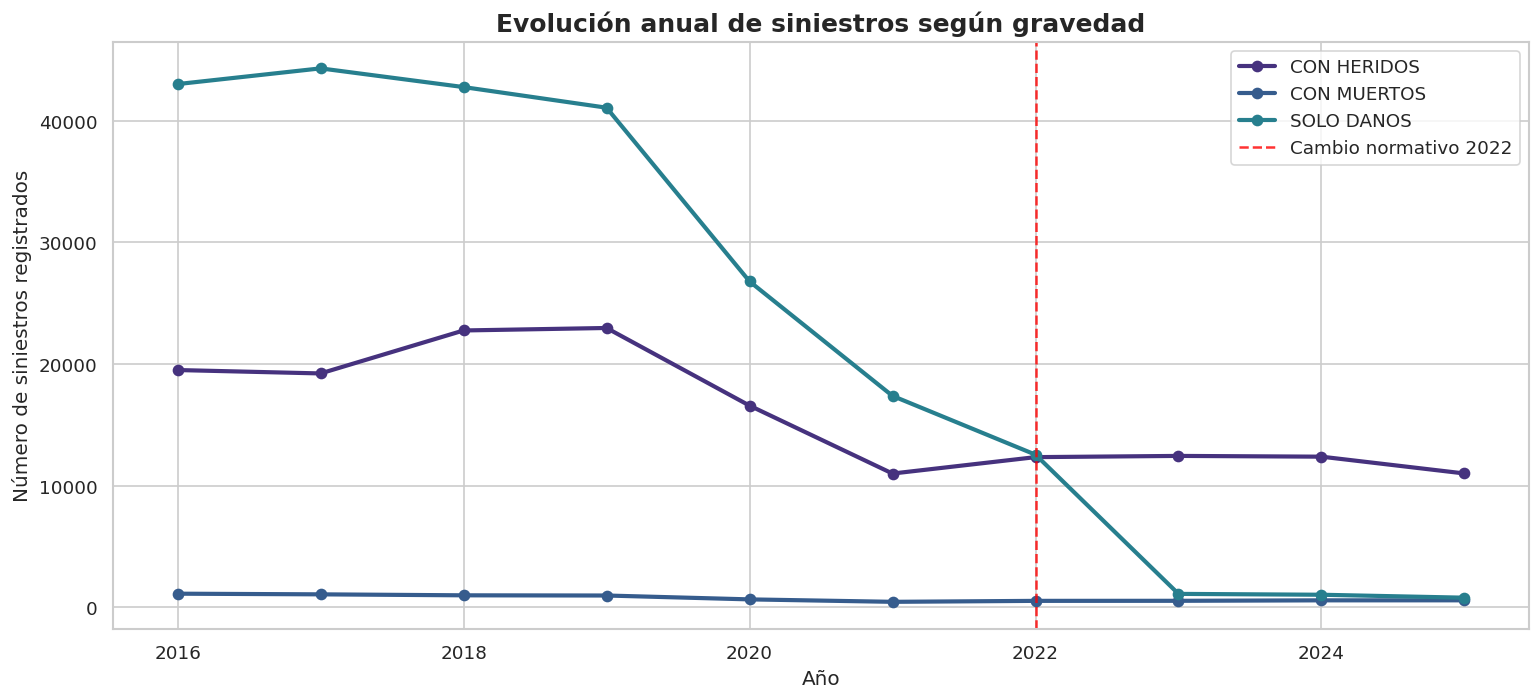

anio,2019,2023,variacion_pct
GRAVEDAD,,,
CON HERIDOS,22970,12455,-45.78
CON MUERTOS,981,546,-44.34
SOLO DANOS,41076,1115,-97.29


In [16]:

# 06. Impacto del cambio de registro sobre la gravedad

tabla_abs = pd.crosstab(
    analisis["anio"],
    analisis["GRAVEDAD"]
)

display(tabla_abs)

fig, ax = plt.subplots(figsize=(13, 6))

tabla_abs.plot(
    kind="line",
    marker="o",
    linewidth=2.5,
    ax=ax
)

ax.axvline(
    2022,
    color="red",
    linestyle="--",
    alpha=0.8,
    label="Cambio normativo 2022"
)

ax.set_title(
    "Evolución anual de siniestros según gravedad",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Año")
ax.set_ylabel("Número de siniestros registrados")
ax.legend()
plt.tight_layout()
plt.show()

# Comparación 2019 vs. 2023
comparacion = tabla_abs.loc[[2019, 2023]].T
comparacion["variacion_pct"] = (
    (comparacion[2023] / comparacion[2019]) - 1
) * 100

display(comparacion.round(2))


### Discontinuidad del registro de siniestros y consecuencias para el modelamiento

La comparación de los registros de siniestralidad vial entre 2022 y 2023 evidencia una reducción del 91,1 % en los eventos clasificados como solo daños materiales, pasando de 12.557 a 1.115 registros. Durante el mismo periodo, los siniestros con heridos aumentaron de 12.355 a 12.455 (+0,8 %) y aquellos clasificados como con muertos pasaron de 541 a 546 (+0,9 %).

Este comportamiento confirma que la reducción en los registros totales se concentra en los siniestros con daños materiales. El fenómeno coincide con la modificación del procedimiento de reporte establecida por el artículo 16 de la Ley 2251 de 2022 y desarrollada mediante la Circular Externa 20224000000057 del Ministerio de Transporte.

En consecuencia, la serie histórica de siniestros totales presenta una discontinuidad que compromete su comparabilidad temporal. Se propone evaluar los siniestros clasificados como con heridos o con muertos como variable objetivo alternativa para el modelo de predicción mensual por localidad.

Esta decisión será validada mediante el análisis de tendencias mensuales, consistencia territorial y disponibilidad de observaciones, antes de establecer definitivamente el periodo de entrenamiento y evaluación.

**Fuentes:** Dataset ACCIDENTE, Secretaría Distrital de Movilidad, versión consultada en octubre de 2026; Ley 2251 de 2022, artículo 16; Ministerio de Transporte, Circular Externa 20224000000057.


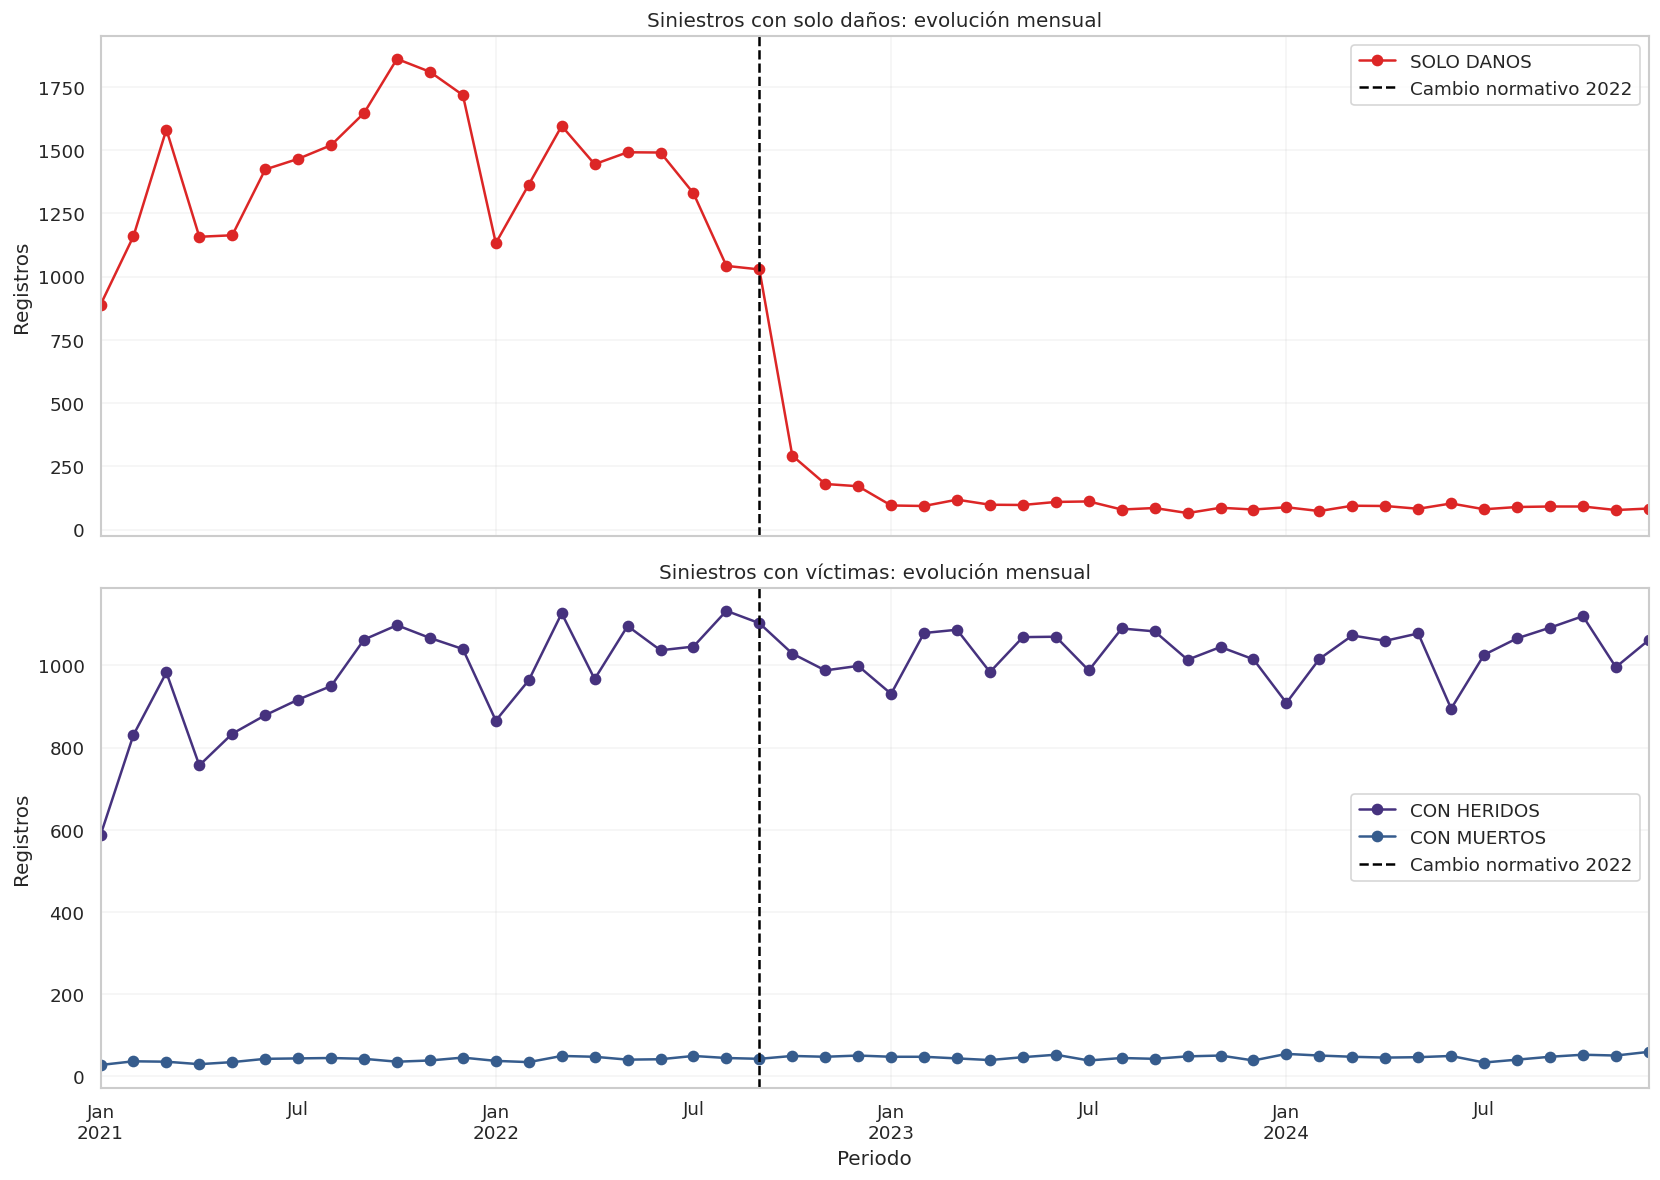

GRAVEDAD,CON HERIDOS,CON MUERTOS,SOLO DANOS
2022-07-01,1046,50,1329
2022-08-01,1133,45,1042
2022-09-01,1103,43,1028
2022-10-01,1029,50,292
2022-11-01,988,48,180
2022-12-01,999,51,171
2023-01-01,931,48,95
2023-02-01,1079,48,93
2023-03-01,1087,44,118


In [17]:

# 07. Análisis mensual del cambio normativo

import matplotlib.pyplot as plt
import pandas as pd

datos_cambio = eda[
    eda["FECHA_ANALISIS"].between(
        "2021-01-01", "2024-12-31"
    )
].copy()

datos_cambio["periodo"] = (
    datos_cambio["FECHA_ANALISIS"]
    .dt.to_period("M").dt.to_timestamp()
)

mensual_gravedad = (
    datos_cambio
    .groupby(["periodo", "GRAVEDAD"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        pd.date_range(
            "2021-01-01",
            "2024-12-01",
            freq="MS"
        ),
        fill_value=0
    )
)

fig, axes = plt.subplots(
    2, 1, figsize=(14, 10), sharex=True
)

mensual_gravedad["SOLO DANOS"].plot(
    ax=axes[0], marker="o",
    color="#dc2626"
)
axes[0].set_title(
    "Siniestros con solo daños: evolución mensual"
)
axes[0].set_ylabel("Registros")

mensual_gravedad[
    ["CON HERIDOS", "CON MUERTOS"]
].plot(
    ax=axes[1], marker="o"
)
axes[1].set_title(
    "Siniestros con víctimas: evolución mensual"
)
axes[1].set_ylabel("Registros")
axes[1].set_xlabel("Periodo")

for ax in axes:
    ax.axvline(
        pd.Timestamp("2022-09-29"),
        color="black",
        linestyle="--",
        label="Cambio normativo 2022"
    )
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

display(
    mensual_gravedad.loc[
        "2022-07":"2023-03"
    ]
)


Número de localidades: 20
Número de meses: 120
Filas del panel: 2400


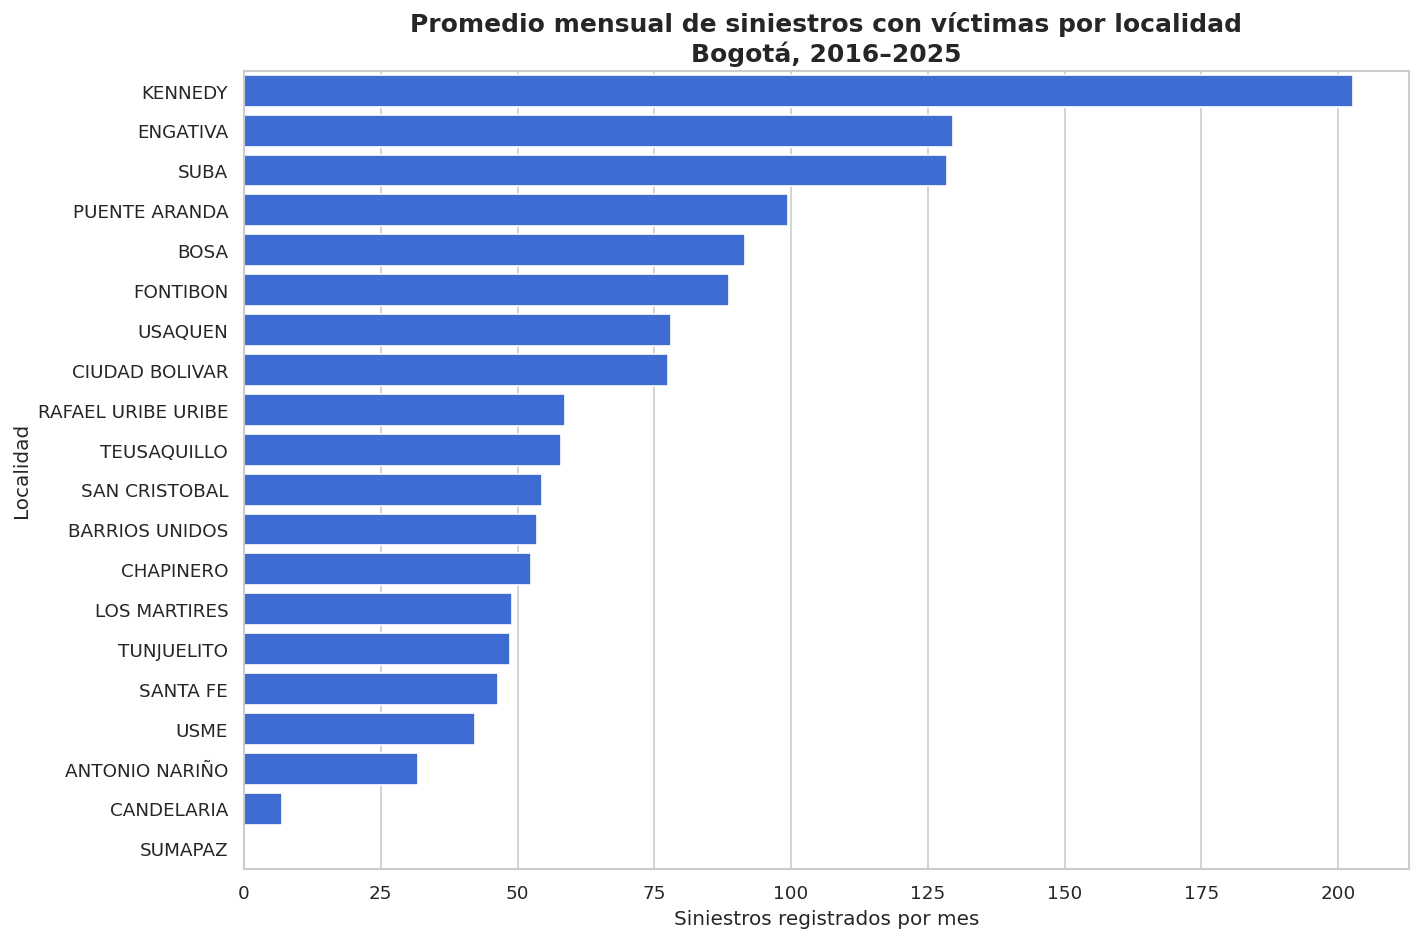

,Promedio mensual
LOCALIDAD,
KENNEDY,202.80
ENGATIVA,129.64
SUBA,128.60
PUENTE ARANDA,99.48
BOSA,91.65
FONTIBON,88.75
USAQUEN,78.02
CIUDAD BOLIVAR,77.47
RAFAEL URIBE URIBE,58.73


In [18]:

# ========================================================
# 08. MATRIZ TEMPORAL Y TERRITORIAL
# Siniestros registrados con heridos o muertos
# ========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

victimas = eda.loc[
    eda["GRAVEDAD"].isin(["CON HERIDOS", "CON MUERTOS"])
    & eda["FECHA_ANALISIS"].dt.year.between(2016, 2025)
].copy()

victimas["PERIODO"] = (
    victimas["FECHA_ANALISIS"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Contar siniestros, NO número de personas lesionadas
mensual_localidad = (
    victimas
    .groupby(["LOCALIDAD", "PERIODO"])
    .size()
    .rename("SINIESTROS")
    .reset_index()
)

# Panel mensual completo para análisis exploratorio
localidades = sorted(eda["LOCALIDAD"].dropna().unique())
meses = pd.date_range(
    "2016-01-01", "2025-12-01", freq="MS"
)

indice = pd.MultiIndex.from_product(
    [localidades, meses],
    names=["LOCALIDAD", "PERIODO"]
)

panel = (
    mensual_localidad
    .set_index(["LOCALIDAD", "PERIODO"])
    .reindex(indice, fill_value=0)
    .reset_index()
)

# Verificar panel
print("Número de localidades:", len(localidades))
print("Número de meses:", len(meses))
print("Filas del panel:", len(panel))

# Promedio mensual por localidad
promedios = (
    panel.groupby("LOCALIDAD")["SINIESTROS"]
    .mean()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(12, 8))

sns.barplot(
    x=promedios.values,
    y=promedios.index,
    color="#2563eb",
    ax=ax
)

ax.set_title(
    "Promedio mensual de siniestros con víctimas por localidad\n"
    "Bogotá, 2016–2025",
    fontsize=15, fontweight="bold"
)
ax.set_xlabel("Siniestros registrados por mes")
ax.set_ylabel("Localidad")

plt.tight_layout()
plt.show()

display(promedios.to_frame("Promedio mensual").round(2))


### Distribución territorial de los siniestros con víctimas

Se construyó un panel exploratorio con periodicidad mensual para las 20 localidades de Bogotá, utilizando los registros clasificados como siniestros con heridos o con muertos durante el periodo 2016–2025. La estructura resultante contiene 2.400 combinaciones de localidad y mes.

Kennedy presenta el mayor promedio mensual de siniestros registrados con víctimas (202,80), seguida de Engativá (129,64), Suba (128,60), Puente Aranda (99,48) y Bosa (91,65).

Los resultados evidencian una distribución territorial heterogénea. Sin embargo, al corresponder a cantidades absolutas, no permiten establecer directamente cuáles localidades presentan mayor riesgo de siniestralidad, puesto que no incorporan medidas de exposición como población, flujos vehiculares o kilómetros recorridos.

Se identificó igualmente una frecuencia extremadamente baja para Sumapaz, lo que requiere evaluar su tratamiento dentro del modelo predictivo. Adicionalmente, las combinaciones mensuales sin registros fueron completadas provisionalmente con ceros, supuesto que deberá validarse antes del entrenamiento.

El siguiente análisis examinará la estabilidad de los patrones territoriales a lo largo del tiempo y la posible presencia de estacionalidad.


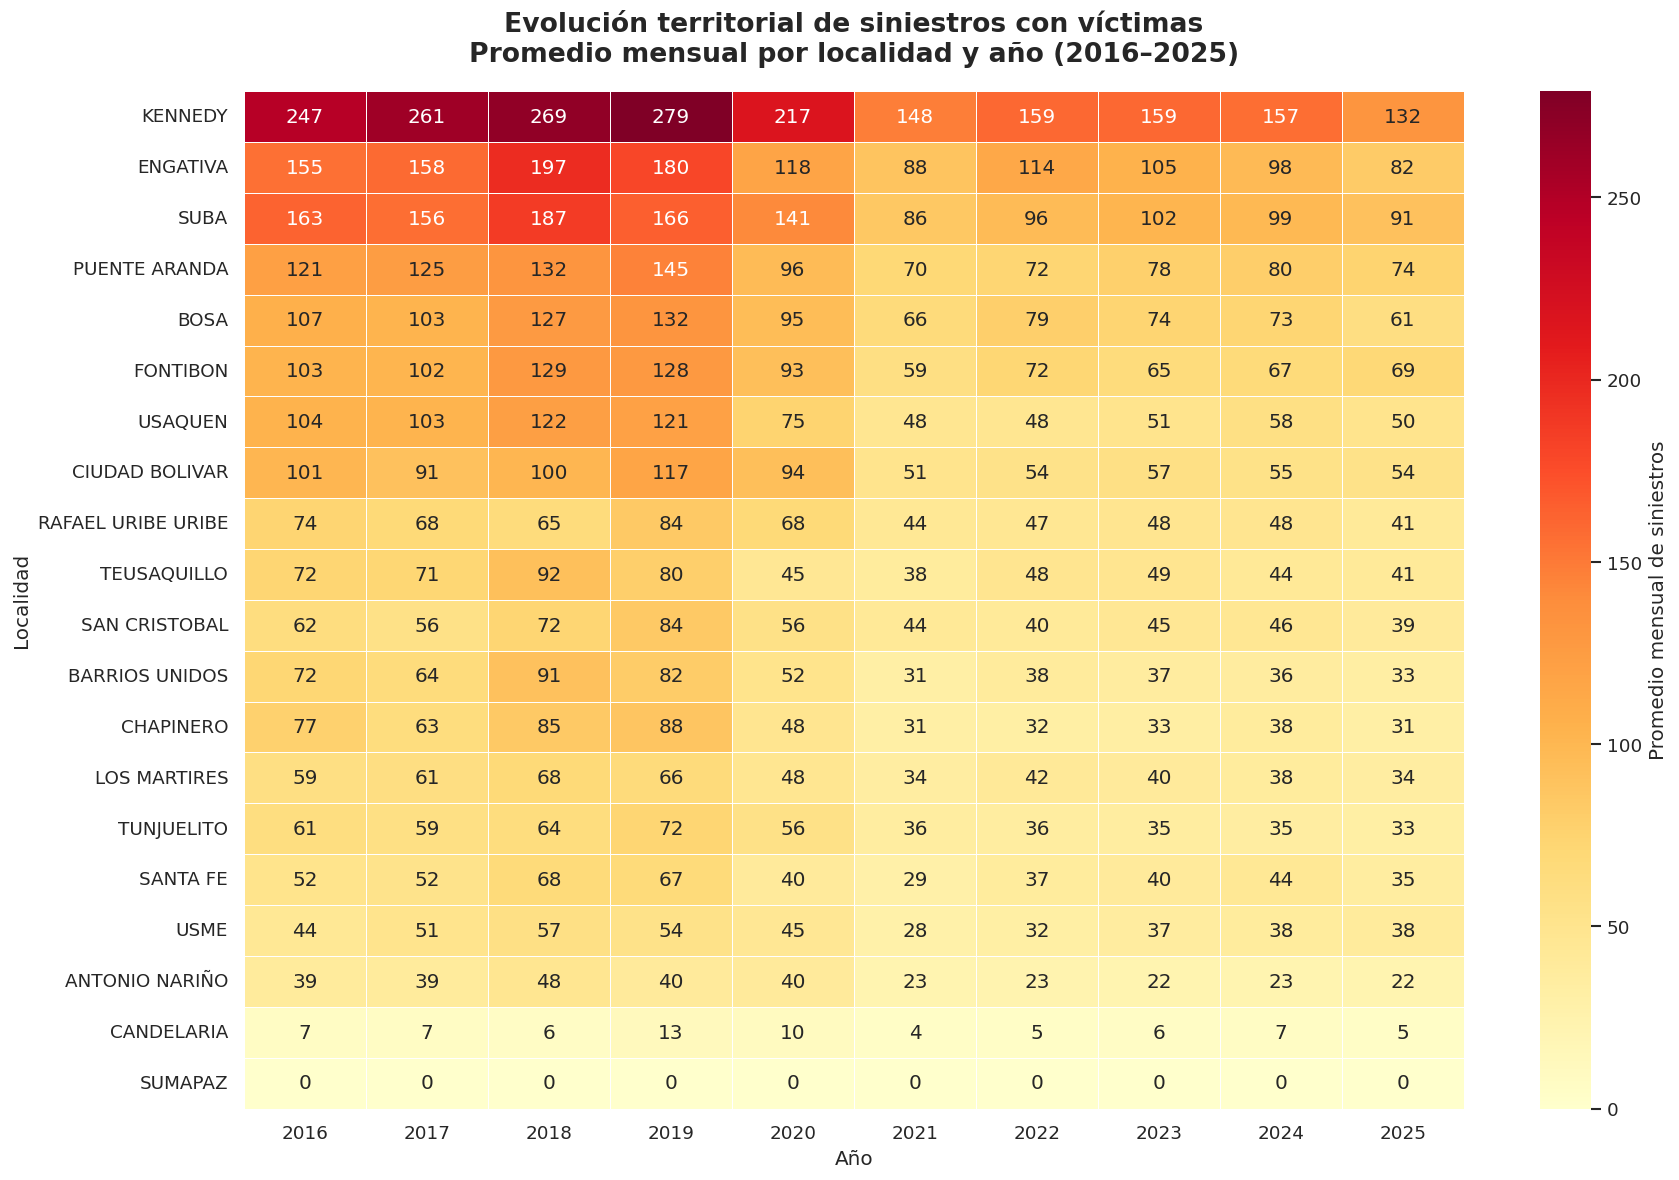

In [19]:

# ========================================================
# 09. MAPA DE CALOR: LOCALIDAD VS. AÑO
# ========================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Partimos del panel creado en la celda 08
panel["ANIO"] = panel["PERIODO"].dt.year

# Media mensual de siniestros por año y localidad
matriz_anual = (
    panel.groupby(["LOCALIDAD", "ANIO"])["SINIESTROS"]
    .mean()
    .unstack("ANIO")
)

# Ordenar localidades por promedio histórico
orden = (
    panel.groupby("LOCALIDAD")["SINIESTROS"]
    .mean()
    .sort_values(ascending=False)
    .index
)

matriz_anual = matriz_anual.loc[orden]

fig, ax = plt.subplots(figsize=(15, 10))

sns.heatmap(
    matriz_anual,
    cmap="YlOrRd",
    linewidths=0.5,
    linecolor="white",
    annot=True,
    fmt=".0f",
    cbar_kws={
        "label": "Promedio mensual de siniestros"
    },
    ax=ax
)

ax.set_title(
    "Evolución territorial de siniestros con víctimas\n"
    "Promedio mensual por localidad y año (2016–2025)",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Año")
ax.set_ylabel("Localidad")

plt.tight_layout()
plt.show()


In [20]:

# 09B. Ceros observados en el panel
# Un cero puede significar ausencia de registros,
# no necesariamente ausencia real de siniestros.

diagnostico_ceros = (
    panel.assign(
        MES_SIN_REGISTROS=panel["SINIESTROS"].eq(0)
    )
    .groupby("LOCALIDAD")
    .agg(
        meses_totales=("SINIESTROS", "size"),
        meses_sin_registros=("MES_SIN_REGISTROS", "sum"),
        promedio_mensual=("SINIESTROS", "mean")
    )
    .sort_values(
        "meses_sin_registros", ascending=False
    )
)

display(diagnostico_ceros.round(2))


,meses_totales,meses_sin_registros,promedio_mensual
LOCALIDAD,,,
SUMAPAZ,120,115,0.04
CANDELARIA,120,1,6.96
BARRIOS UNIDOS,120,0,53.62
ANTONIO NARIÑO,120,0,31.81
BOSA,120,0,91.65
CHAPINERO,120,0,52.52
ENGATIVA,120,0,129.64
CIUDAD BOLIVAR,120,0,77.47
KENNEDY,120,0,202.80


### Heterogeneidad territorial y construcción del panel mensual

El análisis territorial de los siniestros registrados con heridos o muertos, correspondiente al periodo 2016–2025, permitió construir un panel de 2.400 observaciones, distribuidas entre 20 localidades y 120 meses.

Kennedy presenta el mayor promedio mensual de eventos registrados (202,80), seguido de Engativá (129,64) y Suba (128,60). El mapa de calor evidencia diferencias importantes de escala entre localidades y una reducción generalizada en los registros durante 2020–2021.

La evaluación de la continuidad mensual mostró que 18 localidades presentan registros en todos los meses analizados, Candelaria registra un mes sin eventos y Sumapaz presenta 115 meses sin registros. Por su comportamiento excepcionalmente disperso, se propone excluir provisionalmente Sumapaz del modelo predictivo principal, manteniéndola en el análisis descriptivo y documentando esta limitación.

La estructura candidata para el modelamiento comprende, por tanto, 19 localidades y 2.280 observaciones mensuales. Esta selección es provisional y está sujeta a la validación de cobertura, consistencia temporal y desempeño predictivo.


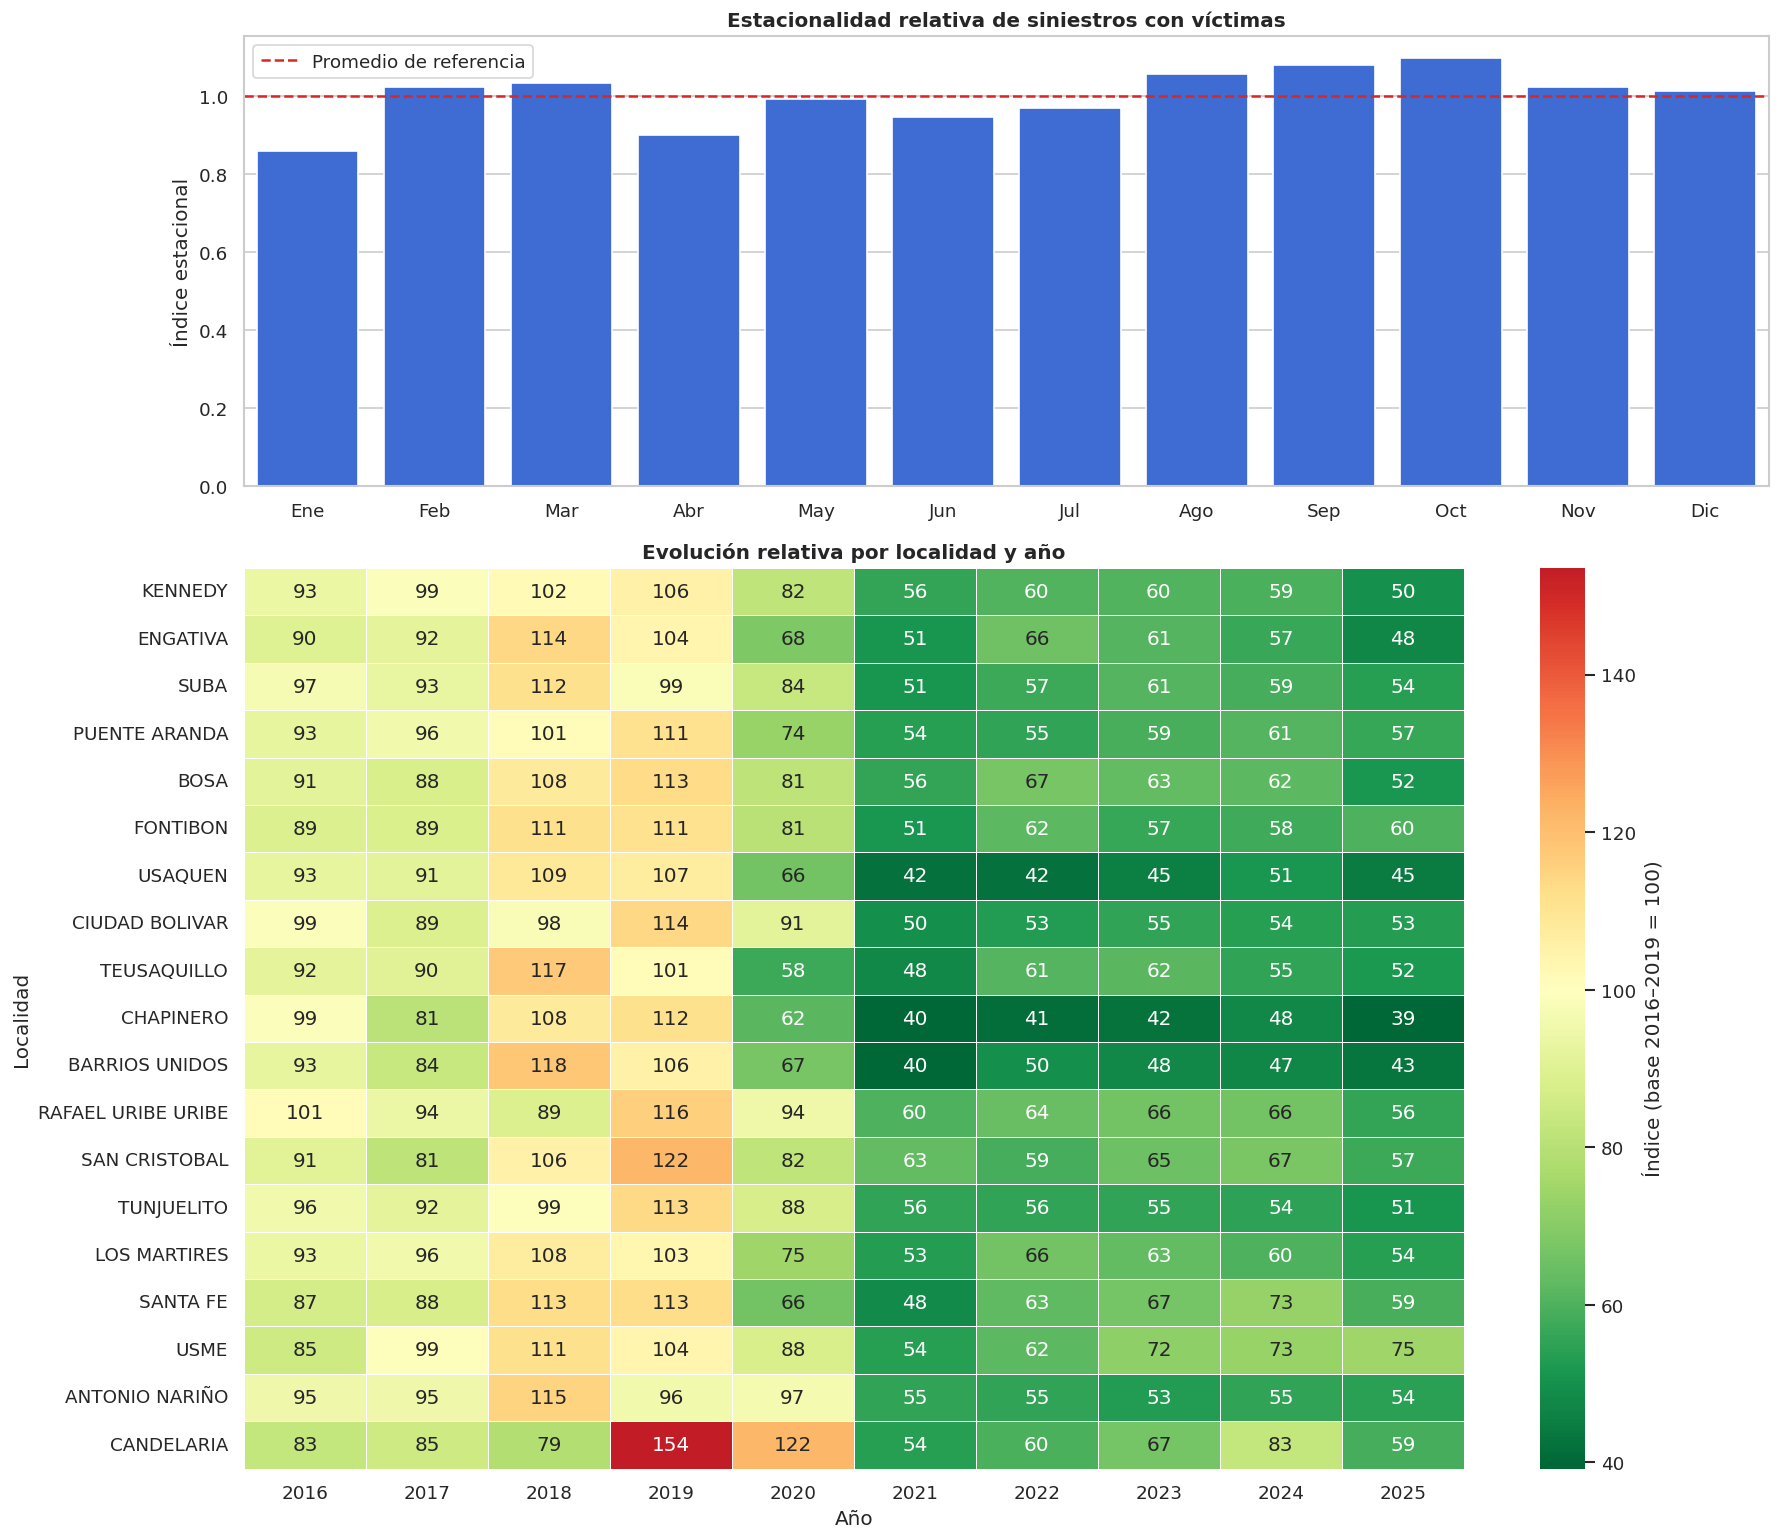

ÍNDICE ESTACIONAL POR MES


,Mes,Índice estacional
0,Ene,0.860
1,Feb,1.022
2,Mar,1.035
3,Abr,0.902
4,May,0.992
5,Jun,0.947
6,Jul,0.969
7,Ago,1.058
8,Sep,1.080
9,Oct,1.099


In [21]:

# ========================================================
# 10. ESTACIONALIDAD Y PATRONES TERRITORIALES
# Siniestros con heridos o muertos, 2016–2025
# ========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

panel_modelo = panel.loc[
    panel["LOCALIDAD"] != "SUMAPAZ"
].copy()

panel_modelo["ANIO"] = panel_modelo["PERIODO"].dt.year
panel_modelo["MES"] = panel_modelo["PERIODO"].dt.month

# A. Estacionalidad relativa:
# cada mes se compara con el promedio de su localidad
# en su mismo año, evitando que años de mayor volumen
# dominen el cálculo.

promedio_localidad_anio = (
    panel_modelo
    .groupby(["LOCALIDAD", "ANIO"])["SINIESTROS"]
    .transform("mean")
)

panel_modelo["INDICE_ESTACIONAL"] = np.where(
    promedio_localidad_anio > 0,
    panel_modelo["SINIESTROS"] / promedio_localidad_anio,
    np.nan
)

estacionalidad = (
    panel_modelo.groupby("MES")["INDICE_ESTACIONAL"]
    .mean()
    .reindex(range(1, 13))
)

# B. Evolución territorial normalizada:
# índice 100 = promedio mensual de cada localidad
# durante 2016–2019 (periodo de referencia).

base = (
    panel_modelo.loc[
        panel_modelo["ANIO"].between(2016, 2019)
    ]
    .groupby("LOCALIDAD")["SINIESTROS"]
    .mean()
)

panel_modelo["BASE_REFERENCIA"] = (
    panel_modelo["LOCALIDAD"].map(base)
)

panel_modelo["INDICE_BASE"] = (
    100 * panel_modelo["SINIESTROS"]
    / panel_modelo["BASE_REFERENCIA"]
)

matriz_normalizada = (
    panel_modelo
    .groupby(["LOCALIDAD", "ANIO"])["INDICE_BASE"]
    .mean()
    .unstack()
)

orden = base.sort_values(ascending=False).index
matriz_normalizada = matriz_normalizada.loc[orden]

fig, axes = plt.subplots(
    2, 1, figsize=(15, 13),
    gridspec_kw={"height_ratios": [1, 2]}
)

# Gráfico de estacionalidad
meses_nombre = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

sns.barplot(
    x=meses_nombre,
    y=estacionalidad.values,
    color="#2563eb",
    ax=axes[0]
)

axes[0].axhline(
    1, color="#dc2626",
    linestyle="--",
    label="Promedio de referencia"
)

axes[0].set_title(
    "Estacionalidad relativa de siniestros con víctimas",
    fontweight="bold"
)
axes[0].set_ylabel("Índice estacional")
axes[0].legend()

# Mapa territorial normalizado
sns.heatmap(
    matriz_normalizada,
    cmap="RdYlGn_r",
    center=100,
    annot=True,
    fmt=".0f",
    linewidths=0.4,
    cbar_kws={
        "label": "Índice (base 2016–2019 = 100)"
    },
    ax=axes[1]
)

axes[1].set_title(
    "Evolución relativa por localidad y año",
    fontweight="bold"
)
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Localidad")

plt.tight_layout()
plt.show()

print("ÍNDICE ESTACIONAL POR MES")
display(
    pd.DataFrame({
        "Mes": meses_nombre,
        "Índice estacional": estacionalidad.values
    }).round(3)
)


### Estacionalidad y evolución relativa de la siniestralidad por localidad

El análisis de estacionalidad relativa, calculado mediante la normalización de los registros mensuales respecto al promedio de cada localidad y año, revela diferencias en la frecuencia de siniestros según el mes calendario. Enero presenta uno de los niveles más bajos, mientras que agosto, septiembre y octubre muestran índices superiores al promedio.

La comparación territorial normalizada, utilizando el promedio de 2016–2019 como referencia, evidencia una disminución generalizada en la cantidad de siniestros registrados con heridos o muertos durante los años posteriores a 2019. Sin embargo, la magnitud de esta reducción varía entre localidades. En 2025, Kennedy presenta un índice cercano a 50, Chapinero a 39 y Usme a 75, en una escala donde 100 representa el promedio del periodo de referencia.

Estas diferencias indican que el comportamiento temporal no es homogéneo en todo el territorio y respaldan la conveniencia de incorporar información específica de cada localidad en el modelo predictivo.

La estacionalidad identificada constituye una característica candidata para el modelamiento, sujeta a la verificación de estabilidad entre diferentes periodos históricos.


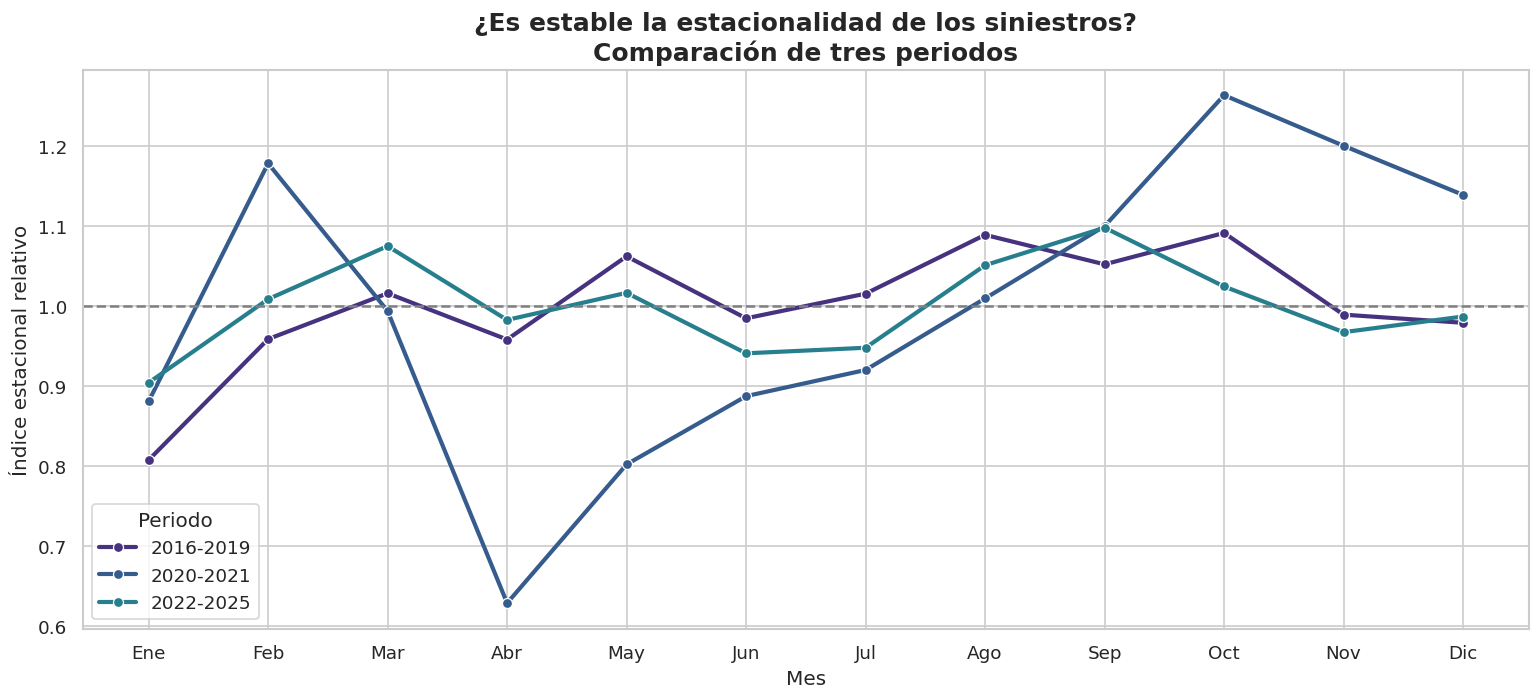

ETAPA,2016-2019,2020-2021,2022-2025
MES,,,
1,0.807,0.880,0.904
2,0.958,1.178,1.008
3,1.016,0.994,1.075
4,0.958,0.628,0.982
5,1.062,0.802,1.016
6,0.984,0.887,0.941
7,1.015,0.920,0.948
8,1.089,1.009,1.051
9,1.052,1.100,1.098


In [22]:

# ========================================================
# 11. ESTABILIDAD DE LA ESTACIONALIDAD MENSUAL
# Comparación entre periodos históricos
# ========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

estabilidad = panel_modelo.copy()

# Periodos de comparación
estabilidad["ETAPA"] = np.select(
    [
        estabilidad["ANIO"].between(2016, 2019),
        estabilidad["ANIO"].between(2020, 2021),
        estabilidad["ANIO"].between(2022, 2025)
    ],
    [
        "2016-2019",
        "2020-2021",
        "2022-2025"
    ],
    default="OTRO"
)

# Normalizamos por localidad y año para reducir
# el efecto de las diferencias de volumen
resumen_estacional = (
    estabilidad
    .groupby(["ETAPA", "MES"])["INDICE_ESTACIONAL"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(13, 6))

sns.lineplot(
    data=resumen_estacional,
    x="MES",
    y="INDICE_ESTACIONAL",
    hue="ETAPA",
    marker="o",
    linewidth=2.5,
    ax=ax
)

ax.axhline(1, color="gray", linestyle="--")
ax.set_xticks(range(1, 13))
ax.set_xticklabels([
    "Ene", "Feb", "Mar", "Abr",
    "May", "Jun", "Jul", "Ago",
    "Sep", "Oct", "Nov", "Dic"
])
ax.set_title(
    "¿Es estable la estacionalidad de los siniestros?\n"
    "Comparación de tres periodos",
    fontsize=15, fontweight="bold"
)
ax.set_ylabel("Índice estacional relativo")
ax.set_xlabel("Mes")
ax.legend(title="Periodo")
plt.tight_layout()
plt.show()

tabla_estacionalidad = (
    resumen_estacional
    .pivot(index="MES", columns="ETAPA",
           values="INDICE_ESTACIONAL")
)

display(tabla_estacionalidad.round(3))


### Estabilidad de patrones estacionales y selección de variables

La comparación de índices estacionales entre los periodos 2016–2019, 2020–2021 y 2022–2025 evidencia patrones recurrentes, aunque con variaciones significativas en su intensidad.

Enero presenta índices inferiores a la unidad en los tres periodos (0,807; 0,880; 0,904), mientras septiembre registra valores superiores (1,052; 1,100; 1,098). Estos resultados sugieren la presencia de componentes estacionales que podrían aportar información al modelo predictivo.

Sin embargo, el comportamiento de 2020–2021 presenta desviaciones importantes, particularmente en abril, lo que advierte sobre la existencia de condiciones excepcionales y posibles cambios estructurales.

En consecuencia, se propone utilizar como características candidatas la localidad, el mes calendario, los rezagos de siniestralidad y los promedios móviles históricos. Estas variables se construirán evitando utilizar información del mes que se pretende predecir.

La utilidad de las características deberá verificarse posteriormente mediante validación temporal y comparación con modelos de referencia.


In [23]:
# ==========================================================
# 12. PREPARACIÓN DEL DATASET PARA MODELAMIENTO
# Predicción: siniestros del mes por localidad
# ==========================================================

import numpy as np
import pandas as pd

modelo_df = (
    panel_modelo[
        ["LOCALIDAD", "PERIODO", "SINIESTROS"]
    ]
    .copy()
    .sort_values(["LOCALIDAD", "PERIODO"])
    .reset_index(drop=True)
)

# Características calendario
modelo_df["MES"] = modelo_df["PERIODO"].dt.month
modelo_df["ANIO"] = modelo_df["PERIODO"].dt.year

# Codificación cíclica del mes
modelo_df["MES_SIN"] = np.sin(
    2 * np.pi * modelo_df["MES"] / 12
)
modelo_df["MES_COS"] = np.cos(
    2 * np.pi * modelo_df["MES"] / 12
)

# Agrupar por localidad para evitar mezclar territorios
grupo = modelo_df.groupby("LOCALIDAD")["SINIESTROS"]

# Rezagos: solo información histórica
for rezago in [1, 3, 6, 12]:
    modelo_df[f"LAG_{rezago}"] = grupo.shift(rezago)

# Medias móviles desplazadas un mes
for ventana in [3, 6, 12]:
    modelo_df[f"MEDIA_MOVIL_{ventana}"] = (
        modelo_df
        .groupby("LOCALIDAD")["SINIESTROS"]
        .transform(
            lambda s: s.shift(1).rolling(
                ventana, min_periods=ventana
            ).mean()
        )
    )

# Indicador histórico de contexto
modelo_df["PERIODO_2020_2021"] = (
    modelo_df["ANIO"].between(2020, 2021)
).astype(int)

# Eliminar solo las filas sin historial suficiente
modelo_ml = modelo_df.dropna(
    subset=[
        "LAG_12",
        "MEDIA_MOVIL_12"
    ]
).copy()

print("Registros del panel original:", len(modelo_df))
print("Registros listos para ML:", len(modelo_ml))
print("Número de localidades:",
      modelo_ml["LOCALIDAD"].nunique())

print("\nIntervalo temporal:")
print(
    modelo_ml["PERIODO"].min(),
    "a",
    modelo_ml["PERIODO"].max()
)

print("\nPrimeras observaciones:")
display(modelo_ml.head(10))

print("\nValores nulos:")
display(modelo_ml.isna().sum().to_frame("Nulos"))

Registros del panel original: 2280
Registros listos para ML: 2052
Número de localidades: 19

Intervalo temporal:
2017-01-01 00:00:00 a 2025-12-01 00:00:00

Primeras observaciones:


,LOCALIDAD,PERIODO,SINIESTROS,MES,ANIO,MES_SIN,MES_COS,LAG_1,LAG_3,LAG_6,LAG_12,MEDIA_MOVIL_3,MEDIA_MOVIL_6,MEDIA_MOVIL_12,PERIODO_2020_2021
12,ANTONIO NARIÑO,2017-01-01,28,1,2017,5.000000e-01,8.660254e-01,28.0,38.0,46.0,30.0,36.000000,42.666667,39.166667,0
13,ANTONIO NARIÑO,2017-02-01,28,2,2017,8.660254e-01,5.000000e-01,28.0,42.0,66.0,14.0,32.666667,39.666667,39.000000,0
14,ANTONIO NARIÑO,2017-03-01,46,3,2017,1.000000e+00,6.123234e-17,28.0,28.0,36.0,32.0,28.000000,33.333333,40.166667,0
15,ANTONIO NARIÑO,2017-04-01,42,4,2017,8.660254e-01,-5.000000e-01,46.0,28.0,38.0,36.0,34.000000,35.000000,41.333333,0
16,ANTONIO NARIÑO,2017-05-01,28,5,2017,5.000000e-01,-8.660254e-01,42.0,28.0,42.0,52.0,38.666667,35.666667,41.833333,0
17,ANTONIO NARIÑO,2017-06-01,40,6,2017,1.224647e-16,-1.000000e+00,28.0,46.0,28.0,50.0,38.666667,33.333333,39.833333,0
18,ANTONIO NARIÑO,2017-07-01,34,7,2017,-5.000000e-01,-8.660254e-01,40.0,42.0,28.0,46.0,36.666667,35.333333,39.000000,0
19,ANTONIO NARIÑO,2017-08-01,50,8,2017,-8.660254e-01,-5.000000e-01,34.0,28.0,28.0,66.0,34.000000,36.333333,38.000000,0
20,ANTONIO NARIÑO,2017-09-01,46,9,2017,-1.000000e+00,-1.836970e-16,50.0,40.0,46.0,36.0,41.333333,40.000000,36.666667,0
21,ANTONIO NARIÑO,2017-10-01,52,10,2017,-8.660254e-01,5.000000e-01,46.0,34.0,42.0,38.0,43.333333,40.000000,37.500000,0



Valores nulos:


,Nulos
LOCALIDAD,0
PERIODO,0
SINIESTROS,0
MES,0
ANIO,0
MES_SIN,0
MES_COS,0
LAG_1,0
LAG_3,0
LAG_6,0


## Conclusiones del análisis exploratorio

El análisis exploratorio del conjunto de datos ACCIDENTE de la Secretaría Distrital de Movilidad de Bogotá permitió caracterizar 906.664 registros históricos y evaluar su calidad, cobertura temporal, distribución territorial y comportamiento estacional.

Se identificaron cinco hallazgos principales:

1. **Calidad estructural:** las variables fundamentales para el análisis temporal y territorial presentan altos niveles de completitud, sin fechas inválidas ni códigos de accidente duplicados.

2. **Discontinuidad histórica:** a partir de octubre de 2022 se observa una caída abrupta de los siniestros clasificados como solo daños materiales. Este cambio coincide con la modificación normativa de 2022 que eliminó la obligatoriedad de elaborar el IPAT para este tipo de eventos, lo que limita la comparabilidad de los registros totales.

3. **Concentración territorial:** Kennedy, Engativá y Suba presentan las mayores cantidades de siniestros con víctimas, aunque las diferencias absolutas no constituyen medidas directas de riesgo vial.

4. **Patrones temporales:** se identifican diferencias estacionales, con índices relativamente bajos en enero y superiores al promedio en septiembre. Su intensidad varía entre periodos, especialmente durante 2020–2021.

5. **Viabilidad predictiva:** se construyó un panel mensual con 19 localidades y 2.280 observaciones para 2016–2025. Después de generar características históricas, el conjunto candidato para modelamiento contiene 2.052 observaciones, correspondientes al periodo enero de 2017–diciembre de 2025.

### Decisiones metodológicas

Se propone utilizar como variable objetivo el número mensual de siniestros registrados con heridos o muertos por localidad, en lugar del total de siniestros, debido a la discontinuidad identificada en la categoría de solo daños materiales.

Sumapaz se conserva en el análisis descriptivo, pero se excluye provisionalmente del modelamiento principal debido a su escasa frecuencia de eventos registrados.

Las variables predictoras candidatas comprenden localidad, mes calendario, rezagos de siniestralidad y medias móviles históricas.

### Limitaciones y trabajo posterior

Los resultados corresponden a cantidades registradas y no permiten estimar directamente el riesgo vial sin incorporar medidas de exposición. Las combinaciones mensuales sin registros fueron tratadas provisionalmente como ceros y requieren validación de cobertura.

Antes del despliegue será necesario efectuar particiones cronológicas de entrenamiento, validación y prueba; contrastar modelos frente a referencias temporales sencillas; evaluar el desempeño por localidad; y comprobar la estabilidad del modelo ante cambios en la distribución de los datos.


In [24]:

# ========================================================
# 13. VALIDACIÓN FINAL DEL DATASET PREPARADO
# ========================================================

assert len(modelo_ml) == 2052, \
    "Cantidad inesperada de observaciones"

assert modelo_ml["LOCALIDAD"].nunique() == 19, \
    "Cantidad inesperada de localidades"

assert not modelo_ml.duplicated(
    ["LOCALIDAD", "PERIODO"]
).any(), "Existen periodos duplicados"

assert modelo_ml.isna().sum().sum() == 0, \
    "Existen valores nulos"

# Comprobar la lógica del rezago de un mes
comprobacion = modelo_df.copy()

comprobacion["LAG_1_VERIFICADO"] = (
    comprobacion.groupby("LOCALIDAD")["SINIESTROS"]
    .shift(1)
)

assert (
    comprobacion["LAG_1"]
    .fillna(-1)
    .eq(comprobacion["LAG_1_VERIFICADO"].fillna(-1))
    .all()
), "Error en el cálculo de LAG_1"

print("✓ Dimensiones verificadas")
print("✓ Localidades verificadas")
print("✓ Sin duplicados por localidad y mes")
print("✓ Sin valores nulos")
print("✓ Rezagos correctamente calculados")
print("\nDATASET PREPARADO Y VALIDADO")


✓ Dimensiones verificadas
✓ Localidades verificadas
✓ Sin duplicados por localidad y mes
✓ Sin valores nulos
✓ Rezagos correctamente calculados

DATASET PREPARADO Y VALIDADO


Esta es una prueba controlada para verificar cambios